# South India Power Outage Analysis (2018 – Dec 2024)

Unit-level daily outage records for Andhra Pradesh, Karnataka, Kerala, Tamil Nadu, Telangana, Puducherry and Lakshadweep.

**Sections**
0. Setup, definitions and outage-episode table
1. Total loss per year and overall
2. Outage trend per year
3. State with the most loss
4. Most common outage remark
5. Which outage type occurs most
6. Which fuel / station type has the most outage
7. Average outage duration per year
8. Time to recover, by outage type
9. Key findings (auto-generated)

> **Read this first: how the numbers are defined**
> - **MW-days**: `loss_mw` is a *daily snapshot* of capacity lost. Summing it over days gives MW-days (× 24 / 1000 = GWh-equivalent).
> - **Outage loss vs shortfall**: rows with `shortfall_not_outage = True` are demand / schedule shortfalls (e.g. *Rsd/Low Schedule*), not breakdowns. They are reported **separately** and excluded from "outage loss".
> - **Years are unequal**: 2020 has 292 days of data and 2024 stops on 10 Dec. Yearly comparisons use **average daily MW lost**, not raw totals.
> - **Episodes**: `outage_age_days` is the age of an outage on that day, not its duration. Durations come from an *episode table* (one row per unit outage: `power_station + unit + outage_date`).
> - **`outage_type` is a lifecycle label**: an outage is *Short Duration* for roughly its first 2 weeks, *Long Duration* after that, and *Unit Synchronised* on the day it returns. So "recovery time by outage type" is best read together with recovery time by **cause** (Section 8).

## 0. Setup

In [1]:
import warnings, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})

# ---- Cleaned file from the cleaning step (see data/README.md) ----
CANDIDATES = ['../data/processed/cleaned_south_outage_powerbi.csv.gz', 'data/processed/cleaned_south_outage_powerbi.csv.gz']
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
assert DATA_PATH, 'Data file not found. Set DATA_PATH to your file location.'

try:
    df = pd.read_csv(DATA_PATH)          
except Exception:
    df = pd.read_excel(DATA_PATH)        # fallback if you re-save it as a real Excel file

for c in ['date', 'outage_date', 'expected_sync_date']:
    df[c] = pd.to_datetime(df[c])

print(f'Loaded {DATA_PATH}')
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns | {df.date.min():%d %b %Y} to {df.date.max():%d %b %Y}')

Loaded /mnt/user-data/uploads/cleaned_south_outage__1_.xls
580,825 rows x 20 columns | 01 Jan 2018 to 10 Dec 2024


In [2]:
# Derived columns -----------------------------------------------------------
df['outage_loss_mw'] = df['loss_mw'].where(~df['shortfall_not_outage'], 0.0)   # real outage loss
df['shortfall_mw']   = df['loss_mw'].where(df['shortfall_not_outage'], 0.0)    # demand/schedule shortfall
OUTAGE_TYPES = ['Short Duration Outage', 'Long Duration Outage', 'Planned Outage']
df['is_outage_row'] = df['outage_type'].isin(OUTAGE_TYPES)
df['loss_class'] = np.where(df['shortfall_not_outage'], 'Shortfall (not an outage)', df['cause_category'])

days_obs = df.groupby('Year')['date'].nunique().rename('days_observed')
print('Days of data per year:'); display(days_obs.to_frame().T)

share_short = df.loc[df.shortfall_not_outage, 'loss_mw'].sum() / df['loss_mw'].sum()
print(f'Shortfall rows make up {share_short:.0%} of raw loss_mw. Excluding them from outage loss.')

Days of data per year:


Year,2018,2019,2020,2021,2022,2023,2024
days_observed,365,362,292,365,365,365,345


Shortfall rows make up 38% of raw loss_mw. Excluding them from outage loss.


### Build the outage-episode table
One row per unit outage. Duration = date the unit was last seen in the outage − `outage_date`.
An episode counts as **recovered** if it has a *Unit Synchronised* row or disappears before the final data date; otherwise it is **ongoing** (censored).

> **Data gap handled here:** `outage_date` is blank for most outage rows from mid-Nov 2024 to 10 Dec 2024. It is rebuilt from each unit's earlier days so outages running at the end of the data are tracked and flagged as ongoing rather than silently dropped.

In [3]:
MAX_DATE = df.date.max()

# --- Data gap: outage_date is blank for most outage rows from mid-Nov 2024 onward. ---
# Recover it from the same unit's earlier days (continuous run of outage days); if the run started inside the
# gap, use the first day the unit is seen in that run.
df = df.sort_values(['power_station', 'power_station_unit', 'date']).reset_index(drop=True)
df['outage_date_raw'] = df['outage_date']
_unit = df['power_station'] + '|' + df['power_station_unit']
_is_out = df['outage_type'] != 'No Outage'
_run = (~_is_out).groupby(_unit).cumsum()
_filled = df.groupby([_unit, _run])['outage_date_raw'].ffill()
_first = df.groupby([_unit, _run])['date'].transform('min')
_fix = _is_out & df['outage_date_raw'].isna()
df['outage_date'] = df['outage_date_raw'].where(~_fix, _filled.fillna(_first))
print(f'Recovered outage_date for {_fix.sum():,} outage rows (median date {df.loc[_fix, "date"].median():%d %b %Y}; the gap starts around mid-Nov 2024).')

key = ['power_station', 'power_station_unit', 'outage_date']

er = df[df.outage_date.notna() & ~df.shortfall_not_outage].copy()
er['_sync']    = er.outage_type.eq('Unit Synchronised')
er['_planned'] = er.outage_type.eq('Planned Outage')
er['_long']    = er.outage_type.eq('Long Duration Outage')
er['_short']   = er.outage_type.eq('Short Duration Outage')

episodes = er.groupby(key).agg(
    state=('state_name', 'first'), sector=('sector', 'first'), fuel=('fuel_type', 'first'),
    capacity_mw=('monitored_capacity', 'max'),
    first_seen=('date', 'min'), last_seen=('date', 'max'),
    peak_loss_mw=('loss_mw', 'max'), mw_days=('outage_loss_mw', 'sum'),
    synchronised=('_sync', 'max'), has_planned=('_planned', 'max'),
    has_long=('_long', 'max'), has_short=('_short', 'max')).reset_index()

def most_common(frame, col, ignore):
    f = frame[frame[col] != ignore]
    return f.groupby(key)[col].agg(lambda s: s.value_counts().index[0]).rename(col).reset_index()

for col, ignore, new in [('cause_category', 'No loss', 'cause'), ('remarks', 'No remark', 'remark'),
                         ('Major_Category1', 'Unknown', 'major_category')]:
    m = most_common(er, col, ignore).rename(columns={col: new})
    episodes = episodes.merge(m, on=key, how='left')
episodes['cause'] = episodes['cause'].fillna('Not recorded')
episodes['remark'] = episodes['remark'].fillna('No remark')
episodes['major_category'] = episodes['major_category'].fillna('Unknown')

episodes['episode_type'] = np.select(
    [episodes.has_planned, episodes.has_long, episodes.has_short],
    ['Planned Outage', 'Long Duration Outage', 'Short Duration Outage'], default='Other (sync-day only)')
episodes['recovered'] = episodes.synchronised | (episodes.last_seen < MAX_DATE)
episodes['duration_days'] = (episodes.last_seen - episodes.outage_date).dt.days
episodes['start_year'] = episodes.outage_date.dt.year
episodes['end_year'] = episodes.last_seen.dt.year
episodes['started_before_data'] = episodes.outage_date < df.date.min()

print(f'{len(episodes):,} outage episodes | recovered: {episodes.recovered.mean():.1%} | '
      f'ongoing at end of data: {(~episodes.recovered).sum():,}')
print(f'{episodes.started_before_data.sum():,} episodes began before {df.date.min():%Y} (outage_date is earlier than the data window).')
display(episodes.head())

Recovered outage_date for 1,103 outage rows (median date 27 Nov 2024; the gap starts around mid-Nov 2024).


9,522 outage episodes | recovered: 99.6% | ongoing at end of data: 41
33 episodes began before 2018 (outage_date is earlier than the data window).


,power_station,power_station_unit,outage_date,state,sector,fuel,capacity_mw,first_seen,last_seen,peak_loss_mw,...,has_short,cause,remark,major_category,episode_type,recovered,duration_days,start_year,end_year,started_before_data
0,Adani Power Limited Udupi Tpp,Unit 1,2023-09-26,Karnataka,Private,Coal/Lignite,600.0,2023-09-26,2023-10-03,600.0,...,True,Technical (forced),Main Steam Line Problem,Other / Unclassified,Short Duration Outage,True,7,2023,2023,False
1,Adani Power Limited Udupi Tpp,Unit 1,2023-10-09,Karnataka,Private,Coal/Lignite,600.0,2023-10-09,2023-10-09,600.0,...,False,Technical (forced),Grid Disturbance,Grid & Transmission,Other (sync-day only),True,0,2023,2023,False
2,Adani Power Limited Udupi Tpp,Unit 1,2023-11-08,Karnataka,Private,Coal/Lignite,600.0,2023-11-09,2023-11-09,0.0,...,False,Not recorded,Grid Disturbance,Grid & Transmission,Other (sync-day only),True,1,2023,2023,False
3,Adani Power Limited Udupi Tpp,Unit 1,2023-12-10,Karnataka,Private,Coal/Lignite,600.0,2023-12-10,2023-12-10,0.0,...,False,Not recorded,Generator Protection,Electrical & Protection,Other (sync-day only),True,0,2023,2023,False
4,Adani Power Limited Udupi Tpp,Unit 1,2024-01-19,Karnataka,Private,Coal/Lignite,600.0,2024-01-19,2024-01-20,600.0,...,False,Planned maintenance,Boiler Inspection/ Re- Certification,Planned Maintenance,Planned Outage,True,1,2024,2024,False


## 1. Total loss due to outage: per year and overall

In [4]:
yearly = df.groupby('Year').agg(outage_MW_days=('outage_loss_mw', 'sum'),
                                shortfall_MW_days=('shortfall_mw', 'sum')).join(days_obs)
yearly['outage_GWh_equiv'] = yearly.outage_MW_days * 24 / 1000
yearly['avg_daily_outage_MW'] = yearly.outage_MW_days / yearly.days_observed

overall = pd.DataFrame({'outage_MW_days': [yearly.outage_MW_days.sum()],
                        'shortfall_MW_days': [yearly.shortfall_MW_days.sum()],
                        'days_observed': [yearly.days_observed.sum()]}, index=['Overall'])
overall['outage_GWh_equiv'] = overall.outage_MW_days * 24 / 1000
overall['avg_daily_outage_MW'] = overall.outage_MW_days / overall.days_observed

total_table = pd.concat([yearly, overall])
display(total_table.style.format('{:,.0f}'))

,outage_MW_days,shortfall_MW_days,days_observed,outage_GWh_equiv,avg_daily_outage_MW
2018,"4,984,888","1,314,546",365,"119,637","13,657"
2019,"5,215,108","2,429,636",362,"125,163","14,406"
2020,"5,602,098","2,479,087",292,"134,450","19,185"
2021,"5,267,668","3,109,479",365,"126,424","14,432"
2022,"4,473,770","3,342,473",365,"107,370","12,257"
2023,"3,304,285","3,712,468",365,"79,303","9,053"
2024,"3,034,323","3,148,812",345,"72,824","8,795"
Overall,"31,882,138","19,536,502","2,459","765,171","12,965"


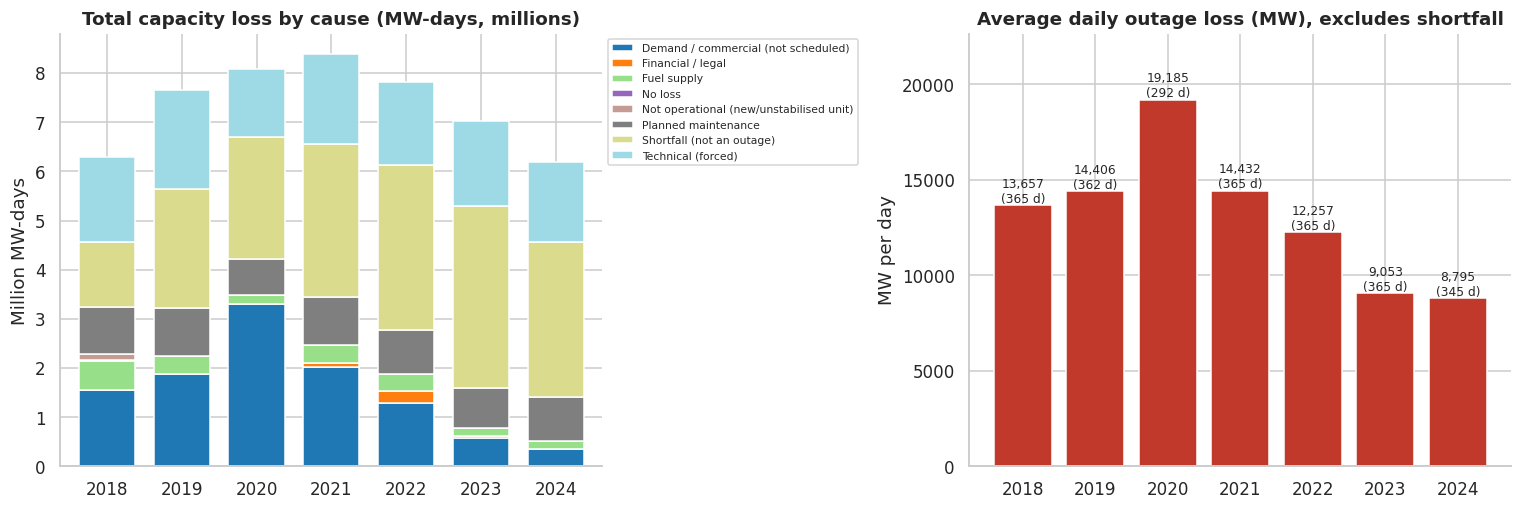

In [5]:
cause_by_year = (df[df.loss_mw > 0].pivot_table(index='Year', columns='loss_class', values='loss_mw',
                                                aggfunc='sum', fill_value=0) / 1e6)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
cause_by_year.plot(kind='bar', stacked=True, ax=ax[0], colormap='tab20', width=0.75)
ax[0].set_title('Total capacity loss by cause (MW-days, millions)')
ax[0].set_ylabel('Million MW-days'); ax[0].set_xlabel('')
ax[0].legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1)); ax[0].tick_params(axis='x', rotation=0)

ax[1].bar(yearly.index.astype(str), yearly.avg_daily_outage_MW, color='#c0392b')
for i, (y, r) in enumerate(yearly.iterrows()):
    ax[1].text(i, r.avg_daily_outage_MW, f'{r.avg_daily_outage_MW:,.0f}\n({int(r.days_observed)} d)', ha='center', va='bottom', fontsize=8)
ax[1].set_title('Average daily outage loss (MW), excludes shortfall')
ax[1].set_ylabel('MW per day'); ax[1].set_ylim(0, yearly.avg_daily_outage_MW.max() * 1.18)
plt.tight_layout(); plt.show()

## 2. Trend of outages per year

In [6]:
trend = yearly[['avg_daily_outage_MW']].copy()
trend['YoY_%'] = trend.avg_daily_outage_MW.pct_change() * 100
new_eps = episodes[episodes.start_year >= df.Year.min()].groupby('start_year').size().rename('new_outage_episodes')
unit_days = df[df.is_outage_row].groupby('Year').size().rename('outage_unit_days')
trend = trend.join(new_eps).join(unit_days)
trend['new_episodes_per_100_days'] = trend.new_outage_episodes / yearly.days_observed * 100
display(trend.style.format({'avg_daily_outage_MW': '{:,.0f}', 'YoY_%': '{:+.1f}%', 'new_outage_episodes': '{:,.0f}',
                            'outage_unit_days': '{:,.0f}', 'new_episodes_per_100_days': '{:.1f}'}, na_rep='-'))

,avg_daily_outage_MW,YoY_%,new_outage_episodes,outage_unit_days,new_episodes_per_100_days
Year,,,,,
2018,"13,657",-,"1,086","13,414",297.5
2019,"14,406",+5.5%,"1,175","14,108",324.6
2020,"19,185",+33.2%,901,"16,691",308.6
2021,"14,432",-24.8%,"1,236","14,728",338.6
2022,"12,257",-15.1%,"2,056","11,949",563.3
2023,"9,053",-26.1%,"1,493","8,765",409.0
2024,"8,795",-2.8%,"1,542","7,876",447.0


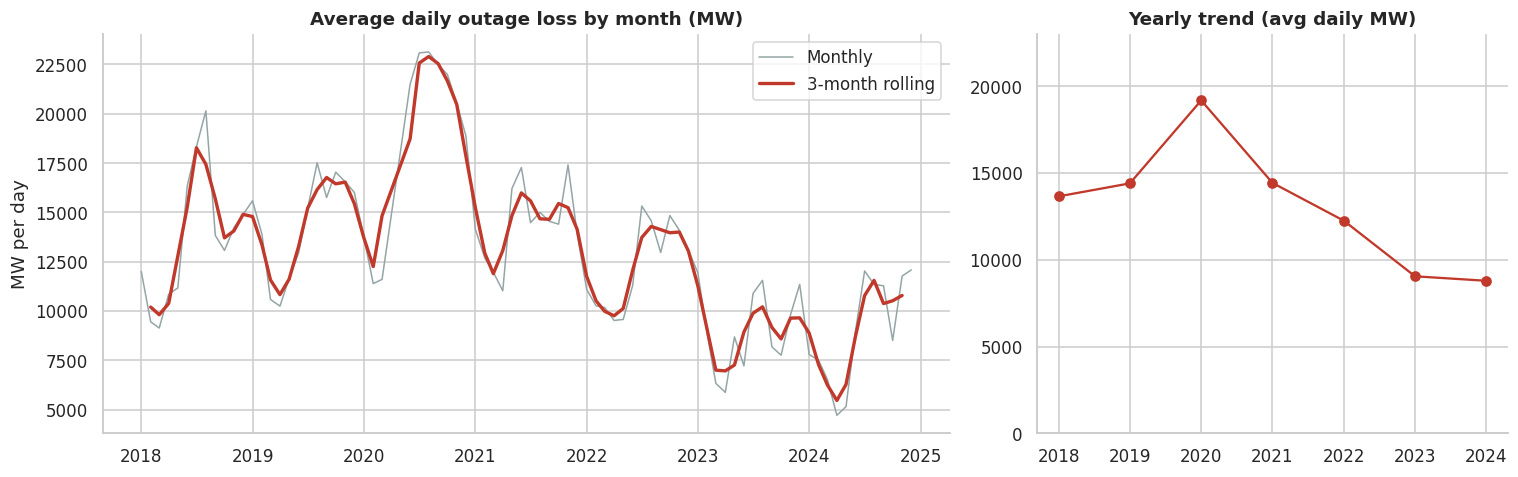

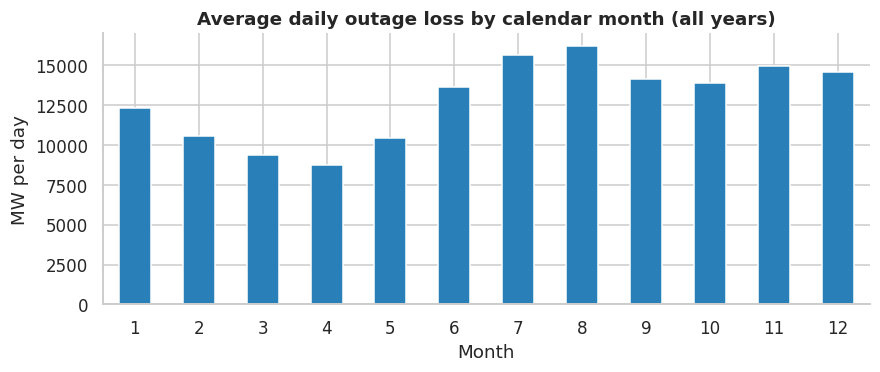

In [7]:
monthly = df.groupby(df.date.dt.to_period('M')).agg(mw=('outage_loss_mw', 'sum'), d=('date', 'nunique'))
monthly['avg_daily_MW'] = monthly.mw / monthly.d
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [1.8, 1]})
ax[0].plot(monthly.index, monthly.avg_daily_MW, color='#95a5a6', lw=1, label='Monthly')
ax[0].plot(monthly.index, monthly.avg_daily_MW.rolling(3, center=True).mean(), color='#c0392b', lw=2.2, label='3-month rolling')
ax[0].set_title('Average daily outage loss by month (MW)'); ax[0].legend(); ax[0].set_ylabel('MW per day')
ax[1].plot(trend.index.astype(str), trend.avg_daily_outage_MW, marker='o', color='#c0392b')
ax[1].set_title('Yearly trend (avg daily MW)'); ax[1].set_ylim(0, trend.avg_daily_outage_MW.max() * 1.2)
plt.tight_layout(); plt.show()

# Seasonality: which calendar months are worst?
season = df.groupby(df.date.dt.month).agg(mw=('outage_loss_mw', 'sum'), d=('date', 'nunique'))
(season.mw / season.d).plot(kind='bar', figsize=(9, 3.2), color='#2980b9')
plt.title('Average daily outage loss by calendar month (all years)'); plt.xlabel('Month'); plt.ylabel('MW per day')
plt.xticks(rotation=0); plt.show()

## 3. State with the most power loss: per year and overall
Absolute loss favours big states. The **loss rate** (outage loss ÷ monitored capacity) is the fairer comparison.

In [8]:
state_year = df.pivot_table(index='state_name', columns='Year', values='outage_loss_mw', aggfunc='sum', fill_value=0)
state_year['Overall'] = state_year.sum(axis=1)
state_year = state_year.sort_values('Overall', ascending=False)
print('Outage loss by state (MW-days):')
display(state_year.style.format('{:,.0f}'))

top_state = pd.DataFrame({
    'top_state': state_year.drop(columns='Overall').idxmax(),
    'MW_days': state_year.drop(columns='Overall').max(),
    'share_of_year_%': state_year.drop(columns='Overall').max() / state_year.drop(columns='Overall').sum() * 100})
top_state.loc['Overall'] = [state_year.Overall.idxmax(), state_year.Overall.max(), state_year.Overall.max() / state_year.Overall.sum() * 100]
print('State with most outage loss:')
display(top_state.style.format({'MW_days': '{:,.0f}', 'share_of_year_%': '{:.1f}%'}))

Outage loss by state (MW-days):


Year,2018,2019,2020,2021,2022,2023,2024,Overall
state_name,,,,,,,,
Tamil Nadu,"1,752,630","1,605,690","1,831,080","1,899,550","1,700,545","1,478,790","1,210,108","11,478,393"
Karnataka,"1,736,350","2,118,850","1,951,750","1,644,530","1,369,300","784,800","738,500","10,344,080"
Andhra Pradesh,"1,219,540","1,140,900","1,420,320","1,394,030","968,480","756,500","743,970","7,643,740"
Telangana,"276,368","349,668","398,948","329,558","435,445","284,195","341,745","2,415,925"
Kerala,0,0,0,0,0,0,0,0
Puducherry,0,0,0,0,0,0,0,0
Lakshadweep,0,0,0,0,0,0,0,0


State with most outage loss:


,top_state,MW_days,share_of_year_%
Year,,,
2018,Tamil Nadu,"1,752,630",35.2%
2019,Karnataka,"2,118,850",40.6%
2020,Karnataka,"1,951,750",34.8%
2021,Tamil Nadu,"1,899,550",36.1%
2022,Tamil Nadu,"1,700,545",38.0%
2023,Tamil Nadu,"1,478,790",44.8%
2024,Tamil Nadu,"1,210,108",39.9%
Overall,Tamil Nadu,"11,478,393",36.0%


Loss rate = % of monitored capacity lost to outages:


Year,2018,2019,2020,2021,2022,2023,2024,Overall
state_name,,,,,,,,
Tamil Nadu,25.5%,23.9%,33.5%,27.5%,23.9%,20.7%,17.6%,24.4%
Karnataka,34.0%,41.5%,47.6%,32.1%,26.7%,15.3%,15.2%,29.9%
Andhra Pradesh,19.0%,17.4%,26.8%,21.1%,14.6%,11.1%,11.0%,17.0%
Telangana,8.0%,10.0%,14.4%,9.1%,11.7%,7.5%,8.5%,9.7%
Kerala,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
Puducherry,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
Lakshadweep,nan%,nan%,nan%,nan%,0.0%,0.0%,0.0%,0.0%


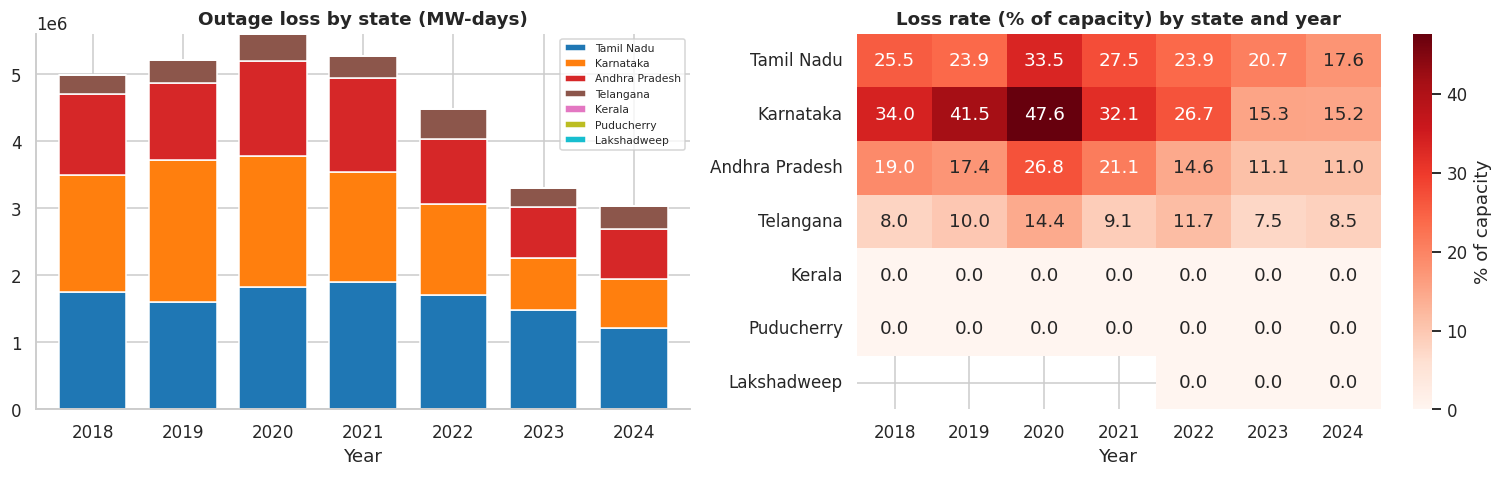

In [9]:
cap = df.dropna(subset=['monitored_capacity'])
sy = cap.groupby(['state_name', 'Year']).agg(loss=('outage_loss_mw', 'sum'), capd=('monitored_capacity', 'sum'))
sy['rate_%'] = sy.loss / sy.capd * 100
rate = sy['rate_%'].unstack()
rate['Overall'] = cap.groupby('state_name').apply(lambda g: g.outage_loss_mw.sum() / g.monitored_capacity.sum() * 100)
rate = rate.loc[state_year.index]
print('Loss rate = % of monitored capacity lost to outages:')
display(rate.style.format('{:.1f}%').background_gradient(cmap='Reds', axis=None))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
state_year.drop(columns='Overall').T.plot(kind='bar', stacked=True, ax=ax[0], colormap='tab10', width=0.75)
ax[0].set_title('Outage loss by state (MW-days)'); ax[0].tick_params(axis='x', rotation=0); ax[0].legend(fontsize=7)
sns.heatmap(rate.drop(columns='Overall'), annot=True, fmt='.1f', cmap='Reds', ax=ax[1], cbar_kws={'label': '% of capacity'})
ax[1].set_title('Loss rate (% of capacity) by state and year'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

**Outage vs shortfall by state.** The tables above cover outages only. Adding shortfall (mostly gas, hydro and low-schedule coal) can change the ranking.

In [10]:
sf = df.groupby('state_name').agg(outage_MW_days=('outage_loss_mw', 'sum'), shortfall_MW_days=('shortfall_mw', 'sum'))
sf['total_MW_days'] = sf.outage_MW_days + sf.shortfall_MW_days
sf = sf.sort_values('total_MW_days', ascending=False)
sf['share_of_total_%'] = sf.total_MW_days / sf.total_MW_days.sum() * 100
display(sf.style.format({'outage_MW_days': '{:,.0f}', 'shortfall_MW_days': '{:,.0f}', 'total_MW_days': '{:,.0f}', 'share_of_total_%': '{:.1f}%'}))
tot_state_year = df.assign(t=df.loss_mw).pivot_table(index='state_name', columns='Year', values='t', aggfunc='sum', fill_value=0)
print('State with most total loss (outage + shortfall) per year:')
print(tot_state_year.idxmax().to_string())

,outage_MW_days,shortfall_MW_days,total_MW_days,share_of_total_%
state_name,,,,
Andhra Pradesh,"7,643,740","9,999,233","17,642,973",34.3%
Tamil Nadu,"11,478,393","3,175,306","14,653,699",28.5%
Karnataka,"10,344,080","2,306,530","12,650,610",24.6%
Telangana,"2,415,925","2,174,656","4,590,580",8.9%
Kerala,0,"1,880,746","1,880,746",3.7%
Puducherry,0,32,32,0.0%
Lakshadweep,0,0,0,0.0%


State with most total loss (outage + shortfall) per year:
Year
2018        Tamil Nadu
2019    Andhra Pradesh
2020    Andhra Pradesh
2021    Andhra Pradesh
2022    Andhra Pradesh
2023    Andhra Pradesh
2024    Andhra Pradesh


## 4. Most common outage remark: per year and overall
Counted as **unit-days** under an outage (Short / Long / Planned), with "No remark" excluded. A second view counts **distinct episodes**.
Note that *Rsd/Low Schedule* is a commercial / low-demand shutdown rather than a breakdown, so a **forced-outage-only** view is included too.

In [11]:
rem = df[df.is_outage_row & (df.remarks != 'No remark')]
overall_rem = rem.groupby('remarks').agg(unit_days=('remarks', 'size'), MW_days=('outage_loss_mw', 'sum'))
overall_rem['episodes'] = episodes.groupby('remark').size()
overall_rem = overall_rem.sort_values('unit_days', ascending=False)
print('Top 10 remarks overall:'); display(overall_rem.head(10).style.format('{:,.0f}', na_rep='-'))

def top_n_per_year(frame, n=3):
    c = frame.groupby(['Year', 'remarks']).size().rename('unit_days').reset_index()
    c['rank'] = c.groupby('Year').unit_days.rank(ascending=False, method='first')
    t = c[c['rank'] <= n].pivot(index='Year', columns='rank', values='remarks')
    t.columns = [f'#{int(x)}' for x in t.columns]
    return t

print('Top 3 remarks per year (all outage rows):'); display(top_n_per_year(rem))
forced = rem[rem.cause_category == 'Technical (forced)']
print('Top 3 remarks per year (forced / technical outages only):'); display(top_n_per_year(forced))

Top 10 remarks overall:


,unit_days,MW_days,episodes
remarks,,,
Rsd/Low Schedule,"23,671","7,195,874",729
Water Wall Tube Leakage,"5,908","2,309,708","1,437"
Reserve Shut Down / Standby Unit,"5,171","1,666,922",493
Boiler Overhaul/ Annual Maintenance,"4,901","1,646,325",180
Annual Maintenance,"3,683","1,299,965",119
Coal Shortage,"3,575","1,760,590",241
Boiler Misc. Problem,"3,015","926,782",384
No Power Purchase Agreement,"3,002","458,400",4
Reactor Maintenance Works.,"2,845","817,900",38


Top 3 remarks per year (all outage rows):


,#1,#2,#3
Year,,,
2018,Rsd/Low Schedule,Boiler Overhaul/ Annual Maintenance,Water Wall Tube Leakage
2019,Rsd/Low Schedule,Boiler Overhaul/ Annual Maintenance,Reserve Shut Down / Standby Unit
2020,Rsd/Low Schedule,Reserve Shut Down / Standby Unit,Water Wall Tube Leakage
2021,Rsd/Low Schedule,Water Wall Tube Leakage,Boiler Misc. Problem
2022,Rsd/Low Schedule,Annual Maintenance,Coal Shortage
2023,Rsd/Low Schedule,Annual Maintenance,Water Wall Tube Leakage
2024,Annual Maintenance,Water Wall Tube Leakage,Boiler Overhaul/ Annual Maintenance


Top 3 remarks per year (forced / technical outages only):


,#1,#2,#3
Year,,,
2018,Water Wall Tube Leakage,Furnace Fire Out /Flame Failure,Electrical Miscellaneous Problems
2019,Water Wall Tube Leakage,Turbine Vibrations High,Furnace Fire Out /Flame Failure
2020,Water Wall Tube Leakage,Boiler Aux. Misc. Promlems,Boiler Misc. Problem
2021,Boiler Misc. Problem,Water Wall Tube Leakage,Boiler Aux. Misc. Promlems
2022,Water Wall Tube Leakage,Boiler Aux. Misc. Promlems,Boiler Misc. Problem
2023,Water Wall Tube Leakage,Boiler Misc. Problem,Boiler Aux. Misc. Promlems
2024,Water Wall Tube Leakage,Boiler Aux. Misc. Promlems,Boiler Misc. Problem


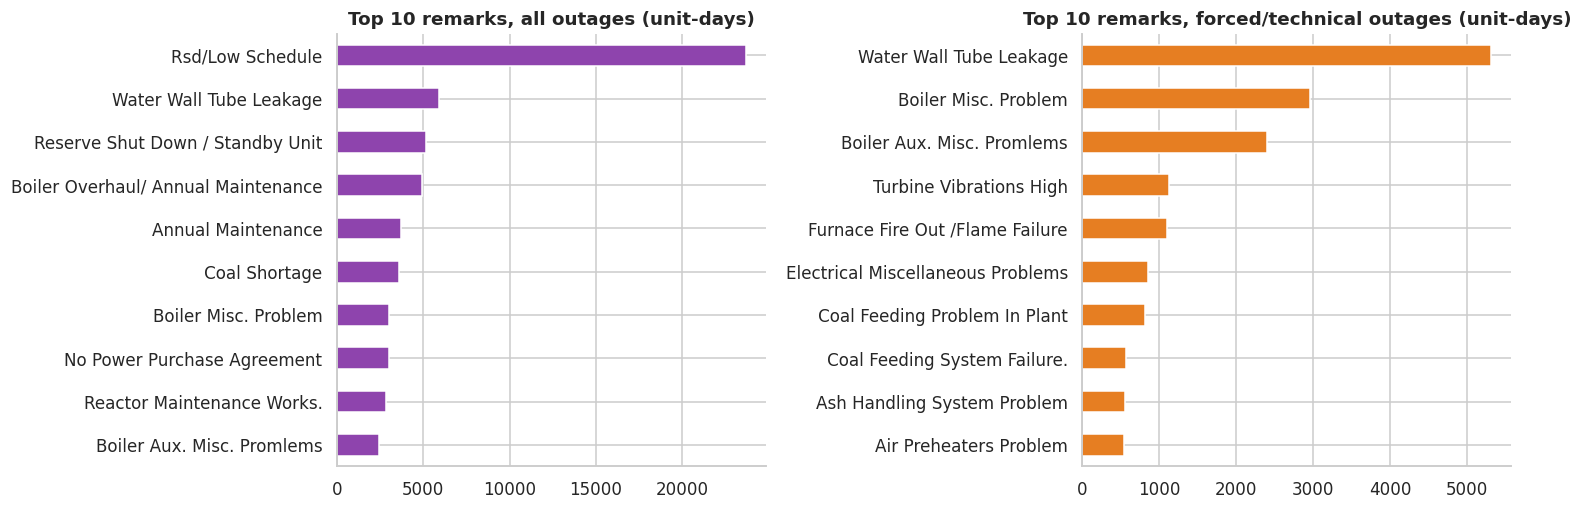

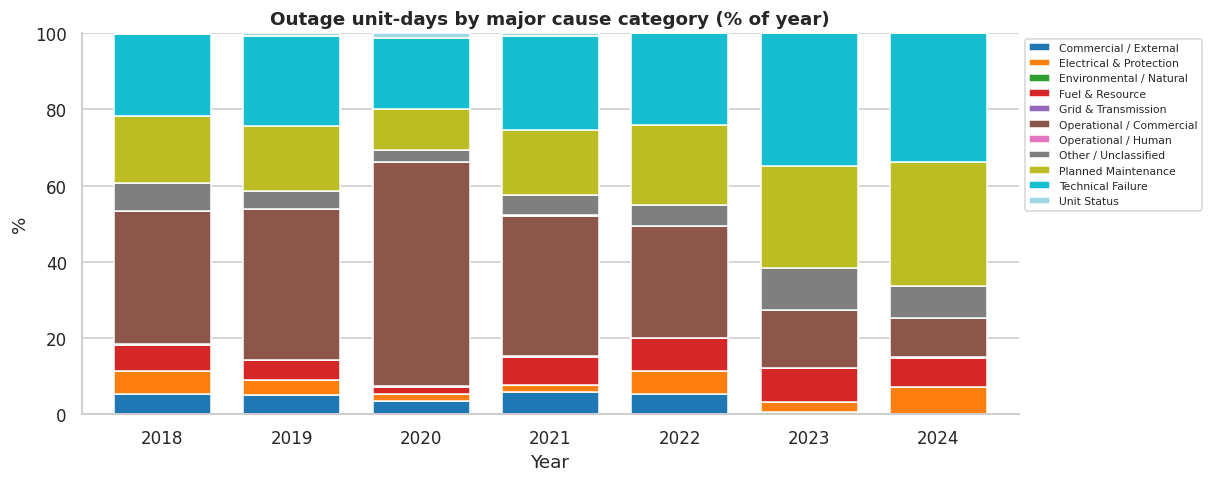

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
overall_rem.head(10)['unit_days'][::-1].plot(kind='barh', ax=ax[0], color='#8e44ad')
ax[0].set_title('Top 10 remarks, all outages (unit-days)'); ax[0].set_ylabel('')
f_over = forced.groupby('remarks').size().sort_values(ascending=False).head(10)
f_over[::-1].plot(kind='barh', ax=ax[1], color='#e67e22')
ax[1].set_title('Top 10 remarks, forced/technical outages (unit-days)'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

mc = (df[df.is_outage_row & (df.Major_Category1 != 'Unknown')]
      .pivot_table(index='Year', columns='Major_Category1', values='remarks', aggfunc='size', fill_value=0))
mc_share = mc.div(mc.sum(axis=1), axis=0) * 100
mc_share.plot(kind='bar', stacked=True, figsize=(11, 4.5), colormap='tab20', width=0.75)
plt.title('Outage unit-days by major cause category (% of year)'); plt.ylabel('%'); plt.xticks(rotation=0)
plt.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1)); plt.show()

## 5. Which outage type occurs most
`outage_type` follows an outage's life (Short → Long → Unit Synchronised). Counting **unit-days** therefore favours long outages, because they stay in the data for many days.
Counting **episodes** (by the longest stage each one reached) shows how often each kind actually starts.

In [13]:
ut = df.groupby('outage_type').agg(unit_days=('outage_type', 'size'), MW_days=('outage_loss_mw', 'sum')).sort_values('unit_days', ascending=False)
ut['share_of_unit_days_%'] = ut.unit_days / ut.unit_days.sum() * 100
print('By unit-days (includes "No Outage" for context):'); display(ut.style.format({'unit_days': '{:,.0f}', 'MW_days': '{:,.0f}', 'share_of_unit_days_%': '{:.1f}%'}))

et = episodes.groupby('episode_type').agg(episodes=('episode_type', 'size'), median_days=('duration_days', 'median'),
                                          MW_days=('mw_days', 'sum')).sort_values('episodes', ascending=False)
et['share_of_episodes_%'] = et.episodes / et.episodes.sum() * 100
print('By distinct episodes:'); display(et.style.format({'episodes': '{:,.0f}', 'median_days': '{:,.0f}', 'MW_days': '{:,.0f}', 'share_of_episodes_%': '{:.1f}%'}))

By unit-days (includes "No Outage" for context):


,unit_days,MW_days,share_of_unit_days_%
outage_type,,,
No Outage,"484,963",0,83.5%
Long Duration Outage,"45,002","14,303,106",7.7%
Short Duration Outage,"27,859","10,316,636",4.8%
Planned Outage,"14,670","5,647,782",2.5%
Unit Synchronised,"8,331","1,614,614",1.4%


By distinct episodes:


,episodes,median_days,MW_days,share_of_episodes_%
episode_type,,,,
Short Duration Outage,"5,378",2,"7,316,547",56.5%
Other (sync-day only),"2,964",0,"434,626",31.1%
Long Duration Outage,692,33,"17,757,270",7.3%
Planned Outage,488,27,"6,373,695",5.1%


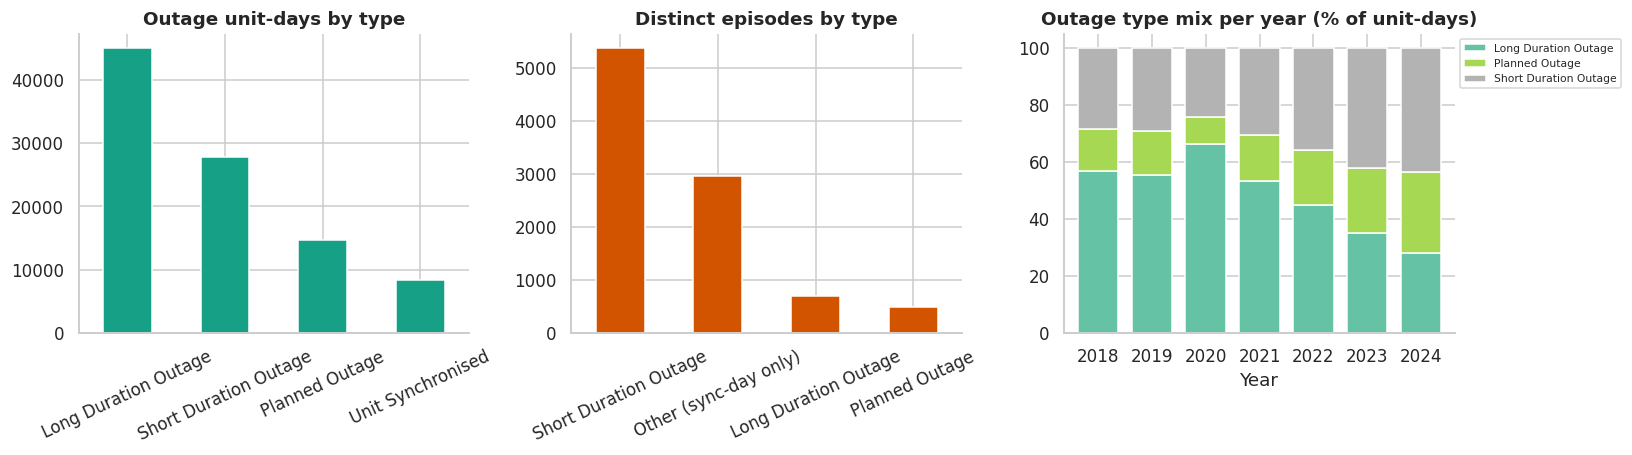

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
ut.drop('No Outage')['unit_days'].plot(kind='bar', ax=ax[0], color='#16a085'); ax[0].set_title('Outage unit-days by type'); ax[0].tick_params(axis='x', rotation=25)
et['episodes'].plot(kind='bar', ax=ax[1], color='#d35400'); ax[1].set_title('Distinct episodes by type'); ax[1].tick_params(axis='x', rotation=25)
yt = df[df.is_outage_row].pivot_table(index='Year', columns='outage_type', values='loss_mw', aggfunc='size', fill_value=0)
yt.div(yt.sum(axis=1), axis=0).mul(100).plot(kind='bar', stacked=True, ax=ax[2], width=0.75, colormap='Set2')
ax[2].set_title('Outage type mix per year (% of unit-days)'); ax[2].tick_params(axis='x', rotation=0); ax[2].legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1))
for a in ax[:2]: a.set_xlabel('')
plt.tight_layout(); plt.show()

## 6. Which station type (fuel) has the most outage
Coal dominates by size, so the **loss rate** shows which fuel is actually the least reliable.

> **Important:** in this dataset, **gas, hydro and diesel have no recorded unit outages**. All of their loss is *shortfall* (generation below capacity: low schedule, no fuel/PPA, water availability). Both views are shown: **outage only** (breakdowns and maintenance) and **outage + shortfall** (everything that kept capacity from producing).

In [15]:
fuel = df.groupby('fuel_type').agg(outage_MW_days=('outage_loss_mw', 'sum'), shortfall_MW_days=('shortfall_mw', 'sum'),
                                   outage_unit_days=('is_outage_row', 'sum'))
fuel['total_loss_MW_days'] = fuel.outage_MW_days + fuel.shortfall_MW_days
fuel['episodes'] = episodes.groupby('fuel').size()
fuel['share_of_outage_%'] = fuel.outage_MW_days / fuel.outage_MW_days.sum() * 100
fuel['share_of_total_loss_%'] = fuel.total_loss_MW_days / fuel.total_loss_MW_days.sum() * 100
fuel['outage_rate_%'] = cap.groupby('fuel_type').apply(lambda g: g.outage_loss_mw.sum() / g.monitored_capacity.sum() * 100)
fuel['total_loss_rate_%'] = cap.groupby('fuel_type').apply(lambda g: (g.outage_loss_mw.sum() + g.shortfall_mw.sum()) / g.monitored_capacity.sum() * 100)
fuel['median_episode_days'] = episodes[episodes.recovered].groupby('fuel').duration_days.median()
fuel = fuel.sort_values('total_loss_MW_days', ascending=False)
display(fuel.style.format({'outage_MW_days': '{:,.0f}', 'shortfall_MW_days': '{:,.0f}', 'total_loss_MW_days': '{:,.0f}',
                           'outage_unit_days': '{:,.0f}', 'episodes': '{:,.0f}', 'share_of_outage_%': '{:.1f}%',
                           'share_of_total_loss_%': '{:.1f}%', 'outage_rate_%': '{:.1f}%', 'total_loss_rate_%': '{:.1f}%',
                           'median_episode_days': '{:,.0f}'}, na_rep='-'))

,outage_MW_days,shortfall_MW_days,outage_unit_days,total_loss_MW_days,episodes,share_of_outage_%,share_of_total_loss_%,outage_rate_%,total_loss_rate_%,median_episode_days
fuel_type,,,,,,,,,,
Coal/Lignite,"29,836,818","1,480,948","82,886","31,317,766","9,399",93.6%,60.9%,28.7%,30.1%,2
Gas,0,"12,097,261",0,"12,097,261",-,0.0%,23.5%,0.0%,76.2%,-
Hydro,0,"5,952,217",0,"5,952,217",-,0.0%,11.6%,0.0%,20.6%,-
Nuclear,"2,045,320","4,300","4,645","2,049,620",123,6.4%,4.0%,25.1%,25.1%,4
Diesel,0,"1,776",0,"1,776",-,0.0%,0.0%,0.0%,0.1%,-


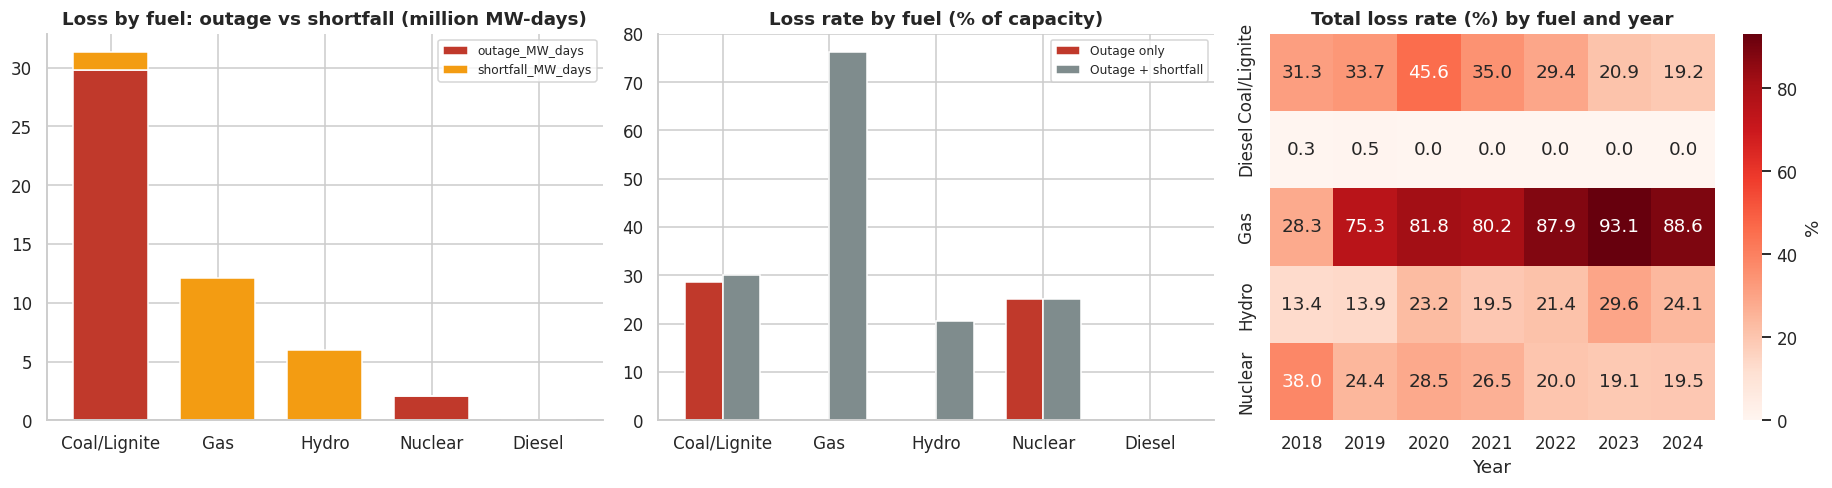

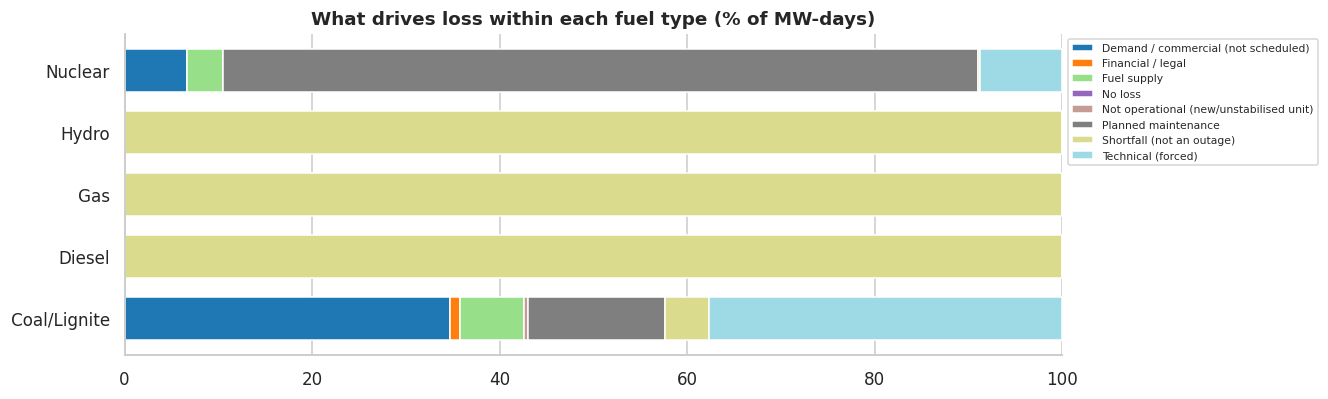

In [16]:
fr = cap.groupby(['fuel_type', 'Year']).apply(
    lambda g: (g.outage_loss_mw.sum() + g.shortfall_mw.sum()) / g.monitored_capacity.sum() * 100).unstack()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
fuel[['outage_MW_days', 'shortfall_MW_days']].div(1e6).plot(kind='bar', stacked=True, ax=ax[0], color=['#c0392b', '#f39c12'], width=0.7)
ax[0].set_title('Loss by fuel: outage vs shortfall (million MW-days)'); ax[0].tick_params(axis='x', rotation=0); ax[0].set_xlabel(''); ax[0].legend(fontsize=8)
fuel[['outage_rate_%', 'total_loss_rate_%']].plot(kind='bar', ax=ax[1], color=['#c0392b', '#7f8c8d'], width=0.7)
ax[1].set_title('Loss rate by fuel (% of capacity)'); ax[1].tick_params(axis='x', rotation=0); ax[1].set_xlabel(''); ax[1].legend(['Outage only', 'Outage + shortfall'], fontsize=8)
sns.heatmap(fr, annot=True, fmt='.1f', cmap='Reds', ax=ax[2], cbar_kws={'label': '%'}); ax[2].set_title('Total loss rate (%) by fuel and year'); ax[2].set_ylabel('')
plt.tight_layout(); plt.show()

fc = (df[df.loss_mw > 0].pivot_table(index='fuel_type', columns='loss_class', values='loss_mw', aggfunc='sum', fill_value=0))
fc.div(fc.sum(axis=1), axis=0).mul(100).plot(kind='barh', stacked=True, figsize=(11, 3.8), colormap='tab20', width=0.7)
plt.title('What drives loss within each fuel type (% of MW-days)'); plt.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1)); plt.ylabel(''); plt.show()

## 7. Average duration of outage per year
Uses **recovered episodes only**, grouped by the **year the outage ended**. Outages still ongoing at the end of the data are excluded, which would otherwise bias the average downward.
The mean is pulled up by a few multi-year outages, so the median and 90th percentile are shown alongside it.

In [17]:
done = episodes[episodes.recovered]
dur = done.groupby('end_year').duration_days.agg(
    episodes='count', mean_days='mean', median_days='median',
    p90_days=lambda s: s.quantile(0.9), max_days='max')
dur['share_over_30d_%'] = done.groupby('end_year').duration_days.apply(lambda s: (s > 30).mean() * 100)
dur['mean_excl_>1yr'] = done[done.duration_days <= 365].groupby('end_year').duration_days.mean()
dur.loc['Overall'] = [len(done), done.duration_days.mean(), done.duration_days.median(), done.duration_days.quantile(.9),
                      done.duration_days.max(), (done.duration_days > 30).mean() * 100,
                      done[done.duration_days <= 365].duration_days.mean()]
display(dur.style.format('{:,.1f}').format({'episodes': '{:,.0f}', 'max_days': '{:,.0f}'}))

,episodes,mean_days,median_days,p90_days,max_days,share_over_30d_%,mean_excl_>1yr
end_year,,,,,,,
2018,"1,077",10.735376,2.000000,25.400000,509,8.913649,9.557728
2019,"1,176",9.531463,2.000000,21.000000,680,7.142857,8.960851
2020,884,16.312217,3.000000,36.000000,961,11.085973,13.436364
2021,"1,257",13.109785,2.000000,29.000000,986,9.148767,11.995219
2022,"2,058",7.831876,1.000000,8.000000,"2,206",3.498542,4.339990
2023,"1,501",9.762825,1.000000,13.000000,"2,283",4.530313,5.288577
2024,"1,528",7.764398,1.000000,10.000000,"2,506",4.253927,4.530184
Overall,"9,481",10.157789,2.000000,18.000000,"2,506",6.307352,7.549482


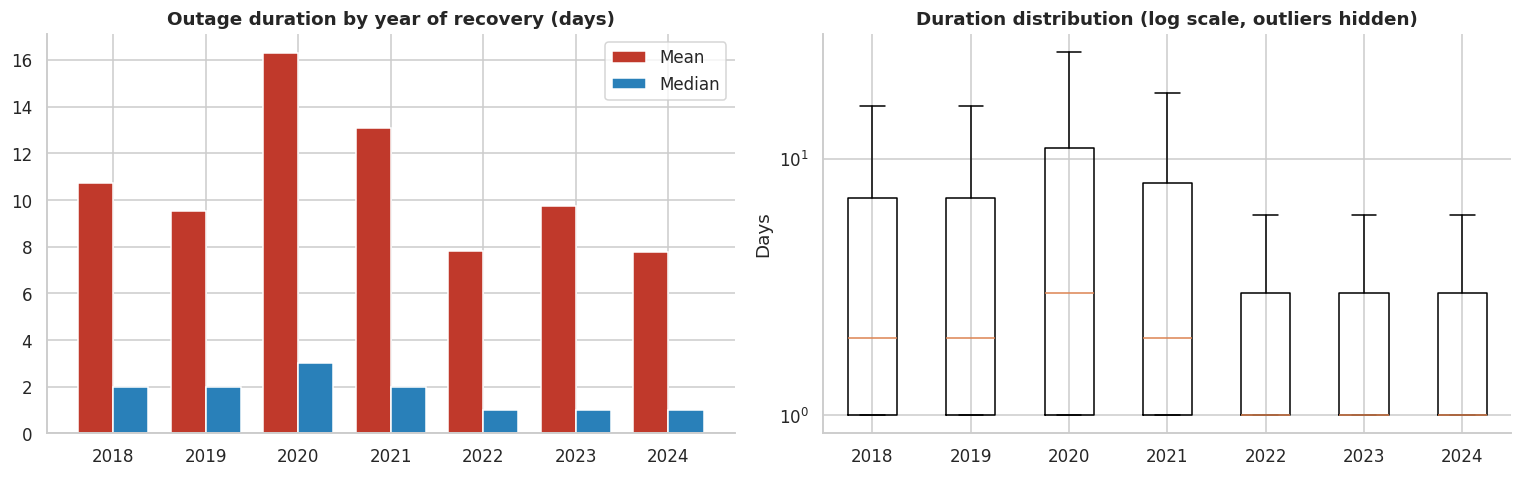

In [18]:
d = dur.drop('Overall'); x = np.arange(len(d)); w = 0.38
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(x - w/2, d.mean_days, w, label='Mean', color='#c0392b'); ax[0].bar(x + w/2, d.median_days, w, label='Median', color='#2980b9')
ax[0].set_xticks(x); ax[0].set_xticklabels(d.index.astype(int)); ax[0].set_title('Outage duration by year of recovery (days)'); ax[0].legend()
data = [done[done.end_year == y].duration_days.clip(lower=1) for y in d.index]
ax[1].boxplot(data, labels=d.index.astype(int), showfliers=False); ax[1].set_yscale('log')
ax[1].set_title('Duration distribution (log scale, outliers hidden)'); ax[1].set_ylabel('Days')
plt.tight_layout(); plt.show()

## 8. Time to recover for each type of outage
Three cuts: by `outage_type` stage, by **cause** (most informative), and by fuel.
Because *Short Duration* means "back within about 15 days" and *Long Duration* means "lasted longer", the type split partly follows from the definition. The cause split shows which kinds of problems actually take longest to fix.

*Note:* "Other (sync-day only)" episodes are units that appear only on the day they were synchronised (0–1 day, cause usually not recorded). They are short trips or data-entry artifacts and pull the overall average down.

In [19]:
def recovery_table(by):
    g = done.groupby(by).duration_days
    t = pd.DataFrame({'episodes': g.size(), 'mean_days': g.mean(), 'median_days': g.median(),
                      'p90_days': g.quantile(.9), 'max_days': g.max()}).sort_values('median_days', ascending=False)
    return t

fmt = {'episodes': '{:,.0f}', 'mean_days': '{:,.1f}', 'median_days': '{:,.1f}', 'p90_days': '{:,.1f}', 'max_days': '{:,.0f}'}
print('By outage type (longest stage reached):'); display(recovery_table('episode_type').style.format(fmt))
print('By cause category:'); display(recovery_table('cause').style.format(fmt))
print('By fuel type:'); display(recovery_table('fuel').style.format(fmt))

By outage type (longest stage reached):


,episodes,mean_days,median_days,p90_days,max_days
episode_type,,,,,
Long Duration Outage,684,87.4,33.0,150.7,"2,506"
Planned Outage,470,35.0,27.5,67.2,324
Short Duration Outage,"5,363",3.3,2.0,8.0,42
Other (sync-day only),"2,964",0.8,0.0,1.0,79


By cause category:


,episodes,mean_days,median_days,p90_days,max_days
cause,,,,,
Financial / legal,4,195.5,113.5,395.6,494
Not operational (new/unstabilised unit),2,96.5,96.5,135.3,145
Planned maintenance,479,35.5,24.0,62.2,"2,506"
Fuel supply,295,16.2,5.0,41.0,229
Demand / commercial (not scheduled),"1,660",24.3,4.0,36.0,"2,283"
Technical (forced),"5,069",6.3,2.0,9.0,"1,057"
Not recorded,"1,972",0.7,0.0,1.0,137


By fuel type:


,episodes,mean_days,median_days,p90_days,max_days
fuel,,,,,
Nuclear,122,39.3,4.5,66.0,"2,506"
Coal/Lignite,"9,359",9.8,2.0,18.0,"2,283"


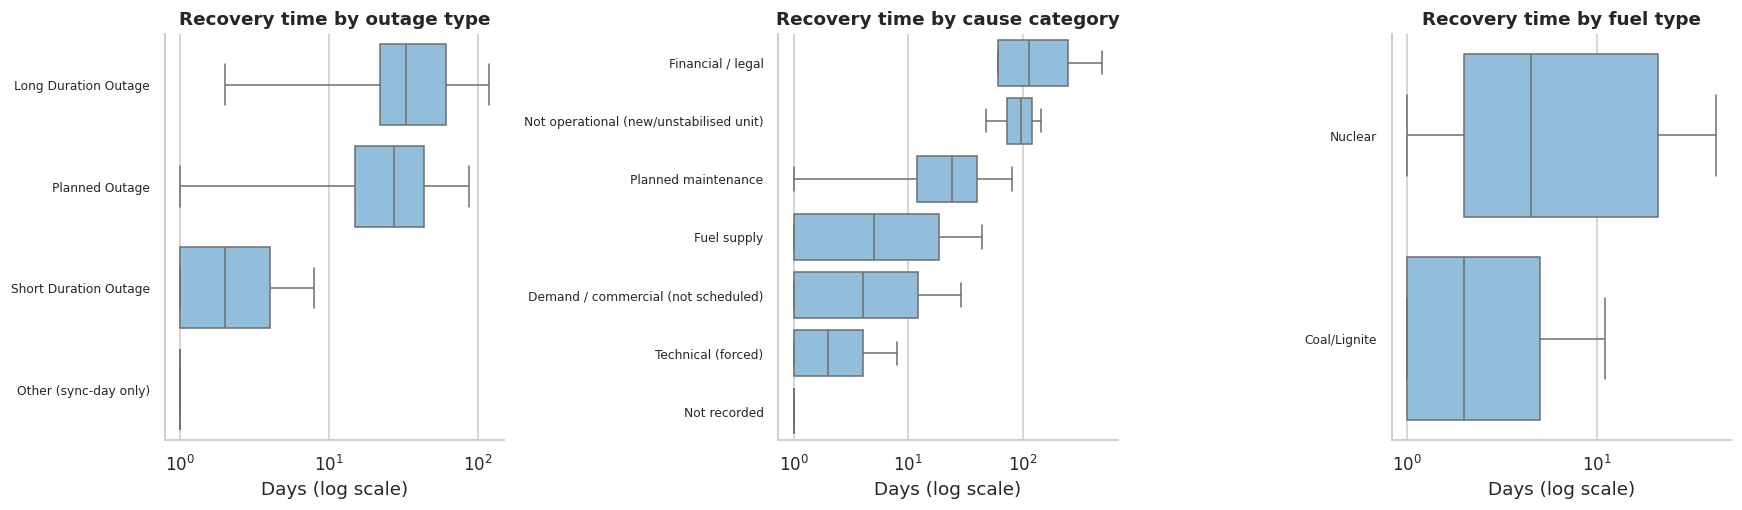

Still down at end of data: 41 episodes, 13,780 MW of capacity. Median age 16 days.


,units,capacity_MW
fuel,,
Coal/Lignite,40,13559.5
Nuclear,1,220.0


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
for a, by, title in zip(ax, ['episode_type', 'cause', 'fuel'], ['Outage type', 'Cause category', 'Fuel type']):
    order = done.groupby(by).duration_days.median().sort_values(ascending=False).index
    sns.boxplot(data=done.assign(d=done.duration_days.clip(lower=1)), y=by, x='d', order=order, ax=a, showfliers=False, color='#85c1e9')
    a.set_xscale('log'); a.set_title(f'Recovery time by {title.lower()}'); a.set_xlabel('Days (log scale)'); a.set_ylabel('')
    a.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

ongoing = episodes[~episodes.recovered]
print(f'Still down at end of data: {len(ongoing):,} episodes, {ongoing.capacity_mw.sum():,.0f} MW of capacity. Median age {(MAX_DATE - ongoing.outage_date).dt.days.median():,.0f} days.')
display(ongoing.groupby('fuel').agg(units=('fuel', 'size'), capacity_MW=('capacity_mw', 'sum')).sort_values('capacity_MW', ascending=False))

## 9. Key findings (auto-generated from the data above)

In [21]:
def top(s): return s.idxmax(), s.max()
yr_top = yearly.avg_daily_outage_MW
peak_y, peak_v = top(yr_top); low_y = yr_top.idxmin()
st_all = state_year.Overall; st_rate = rate.Overall.drop(['Lakshadweep', 'Puducherry'], errors='ignore')
rem_all = overall_rem['unit_days']; frc_all = forced.groupby('remarks').size()
fuel_loss = fuel.outage_MW_days; fuel_rate = fuel['outage_rate_%']; fuel_tot = fuel.total_loss_MW_days; fuel_tot_rate = fuel['total_loss_rate_%']
cause_med = done.groupby('cause').duration_days.median().drop('Not recorded', errors='ignore')

print('1) TOTAL LOSS')
print(f'   Overall outage loss: {yearly.outage_MW_days.sum():,.0f} MW-days (~{yearly.outage_MW_days.sum()*24/1e6:,.1f} million MWh-equivalent). '
      f'Separate shortfall: {yearly.shortfall_MW_days.sum():,.0f} MW-days.')
print(f'   Peak year (avg daily MW): {peak_y} at {peak_v:,.0f} MW/day; lowest: {low_y} at {yr_top.min():,.0f} MW/day.')
print('2) TREND')
print(f'   Avg daily outage MW went from {yr_top.iloc[0]:,.0f} ({yr_top.index[0]}) to {yr_top.iloc[-1]:,.0f} ({yr_top.index[-1]}); peak in {peak_y}.')
print('3) STATE')
print(f'   Most loss overall: {st_all.idxmax()} ({st_all.max()/st_all.sum():.0%} of total). By year: ' + ', '.join(f'{y}: {s}' for y, s in top_state.top_state.drop("Overall").items()))
print(f'   Including shortfall, top state overall: {sf.total_MW_days.idxmax()} ({sf.total_MW_days.max()/sf.total_MW_days.sum():.0%} of total loss).')
print(f'   Highest loss RATE overall (excl. tiny regions): {st_rate.idxmax()} at {st_rate.max():.1f}% of capacity.')
print('4) REMARKS')
print(f'   Most common overall: {rem_all.idxmax()} ({rem_all.max():,} unit-days). Most common forced-outage remark: {frc_all.idxmax()} ({frc_all.max():,}).')
print('5) OUTAGE TYPE')
print(f'   Most unit-days: {ut.drop("No Outage").unit_days.idxmax()}. Most episodes started: {et.episodes.idxmax()} ({et.episodes.max():,}).')
print('6) FUEL')
print(f'   Most loss: {fuel_loss.idxmax()} ({fuel_loss.max()/fuel_loss.sum():.0%} of outage MW-days). Highest loss rate: {fuel_rate.idxmax()} at {fuel_rate.max():.1f}%.')
print(f'   Including shortfall: {fuel_tot.idxmax()} still leads ({fuel_tot.max()/fuel_tot.sum():.0%}); fuels with zero recorded outages (all loss is shortfall): ' + ', '.join(fuel_loss[fuel_loss == 0].index) + f'. Highest total loss rate: {fuel_tot_rate.idxmax()} at {fuel_tot_rate.max():.1f}%.')
print('7) DURATION')
print(f'   Overall median outage lasts {done.duration_days.median():.0f} days (mean {done.duration_days.mean():.0f}). '
      f'Longest average by recovery year: {dur.drop("Overall").mean_days.idxmax()} ({dur.drop("Overall").mean_days.max():.0f} days).')
print('8) RECOVERY')
print(f'   Slowest cause (median days): {cause_med.idxmax()} ({cause_med.max():.0f}). Fastest: {cause_med.idxmin()} ({cause_med.min():.0f}).')
print(f'   {len(ongoing):,} outages were still ongoing when the data ends.')

1) TOTAL LOSS
   Overall outage loss: 31,882,138 MW-days (~765.2 million MWh-equivalent). Separate shortfall: 19,536,502 MW-days.
   Peak year (avg daily MW): 2020 at 19,185 MW/day; lowest: 2024 at 8,795 MW/day.
2) TREND
   Avg daily outage MW went from 13,657 (2018) to 8,795 (2024); peak in 2020.
3) STATE
   Most loss overall: Tamil Nadu (36% of total). By year: 2018: Tamil Nadu, 2019: Karnataka, 2020: Karnataka, 2021: Tamil Nadu, 2022: Tamil Nadu, 2023: Tamil Nadu, 2024: Tamil Nadu
   Including shortfall, top state overall: Andhra Pradesh (34% of total loss).
   Highest loss RATE overall (excl. tiny regions): Karnataka at 29.9% of capacity.
4) REMARKS
   Most common overall: Rsd/Low Schedule (23,671 unit-days). Most common forced-outage remark: Water Wall Tube Leakage (5,309).
5) OUTAGE TYPE
   Most unit-days: Long Duration Outage. Most episodes started: Short Duration Outage (5,378).
6) FUEL
   Most loss: Coal/Lignite (94% of outage MW-days). Highest loss rate: Coal/Lignite at 28.7%

### Next steps (done in Section 10)
- Station-level ranking and a Pareto chart (what share of loss comes from the top 10 stations?)
- Repeat-failure analysis (units that fail again within 30 days of returning)
- Kaplan-Meier survival curves for recovery time (`lifelines`), which handle ongoing outages properly
- Expected vs actual sync date, using `expected_sync_date`
- Monthly forecasting (SARIMA or Prophet)

Remaining ideas: forecast forced loss only (per state / station), add a unit-age or commissioning-year column to test whether older units trip more, and a Cox regression of recovery time on cause, fuel and state.

## 10. Next steps: the reliability view
Sections 1 to 9 answer *how much* and *where*. This part answers *why* and *what next*, using the standard power-sector reliability lens (forced vs planned vs commercial loss, concentration, repeat trips, survival analysis, forecast).
Each analysis below was one of the "possible next steps" listed earlier, now run on the data. Everything uses only pandas / numpy / matplotlib, so it works without extra installs.

### 10.1 Split "outage loss" into forced, planned, commercial and fuel
**Why this matters:** one-third of what the notebook counts as outage loss is *Demand / commercial (not scheduled)*, i.e. reserve shutdown or low schedule. That is a *market* decision, not an equipment failure. A reliability engineer would look at **forced outage rate (FOR)** only, so state and fuel rankings should be re-checked on that basis.

Share of total outage loss by cause (all years, %):
                                         share_%
cause_category                                  
Technical (forced)                         37.60
Planned maintenance                        19.50
Demand / commercial (not scheduled)        34.50
Fuel supply                                 6.90
Financial / legal                           1.10
Not operational (new/unstabilised unit)     0.40
Loss rate by state and cause (% of monitored capacity):
cause_category  Technical (forced)  Planned maintenance  Demand / commercial (not scheduled)  Fuel supply  Financial / legal  Not operational (new/unstabilised unit)
state_name                                                                                                                                                           
Andhra Pradesh                5.69                 2.58                                 6.34         2.33               0.00                                     0.00
Ka

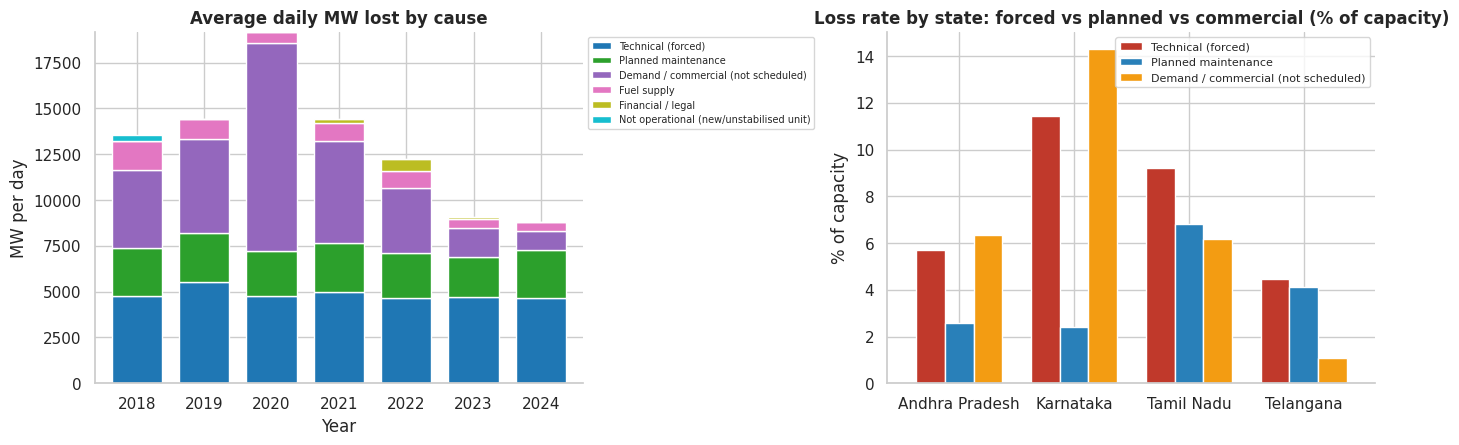

In [ ]:
cap = df.dropna(subset=['monitored_capacity'])
CAUSE_ORDER = ['Technical (forced)', 'Planned maintenance', 'Demand / commercial (not scheduled)', 'Fuel supply',
               'Financial / legal', 'Not operational (new/unstabilised unit)']
cl = df[df.outage_loss_mw > 0].pivot_table(index='Year', columns='cause_category', values='outage_loss_mw', aggfunc='sum', fill_value=0)
cl = cl[[c for c in CAUSE_ORDER if c in cl.columns]]
cl_avg = cl.div(days_obs, axis=0)                      # average daily MW lost, comparable across years

overall_share = (cl.sum() / cl.sum().sum() * 100).round(1)
print('Share of total outage loss by cause (all years, %):'); display(overall_share.to_frame('share_%'))

# Loss rate (% of monitored capacity) by state and cause: forced only vs everything else
den = cap.groupby('state_name').monitored_capacity.sum()
sc = cap[cap.outage_loss_mw > 0].pivot_table(index='state_name', columns='cause_category', values='outage_loss_mw', aggfunc='sum', fill_value=0)
sc_rate = sc.div(den, axis=0).mul(100)[[c for c in CAUSE_ORDER if c in sc.columns]]
sc_rate = sc_rate.loc[~sc_rate.index.isin(['Lakshadweep', 'Puducherry', 'Kerala'])]    # tiny / no thermal base
print('Loss rate by state and cause (% of monitored capacity):'); display(sc_rate.style.format('{:.1f}%').background_gradient(cmap='Reds', axis=None))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
cl_avg.plot(kind='bar', stacked=True, ax=ax[0], colormap='tab10', width=0.75)
ax[0].set_title('Average daily MW lost by cause'); ax[0].set_ylabel('MW per day'); ax[0].tick_params(axis='x', rotation=0)
ax[0].legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1))
sc_rate[['Technical (forced)', 'Planned maintenance', 'Demand / commercial (not scheduled)']].plot(kind='bar', ax=ax[1], width=0.75,
                                                                   color=['#c0392b', '#2980b9', '#f39c12'])
ax[1].set_title('Loss rate by state: forced vs planned vs commercial (% of capacity)'); ax[1].set_ylabel('% of capacity'); ax[1].set_xlabel('')
ax[1].tick_params(axis='x', rotation=0); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 10.2 Station-level Pareto: how concentrated is the loss?

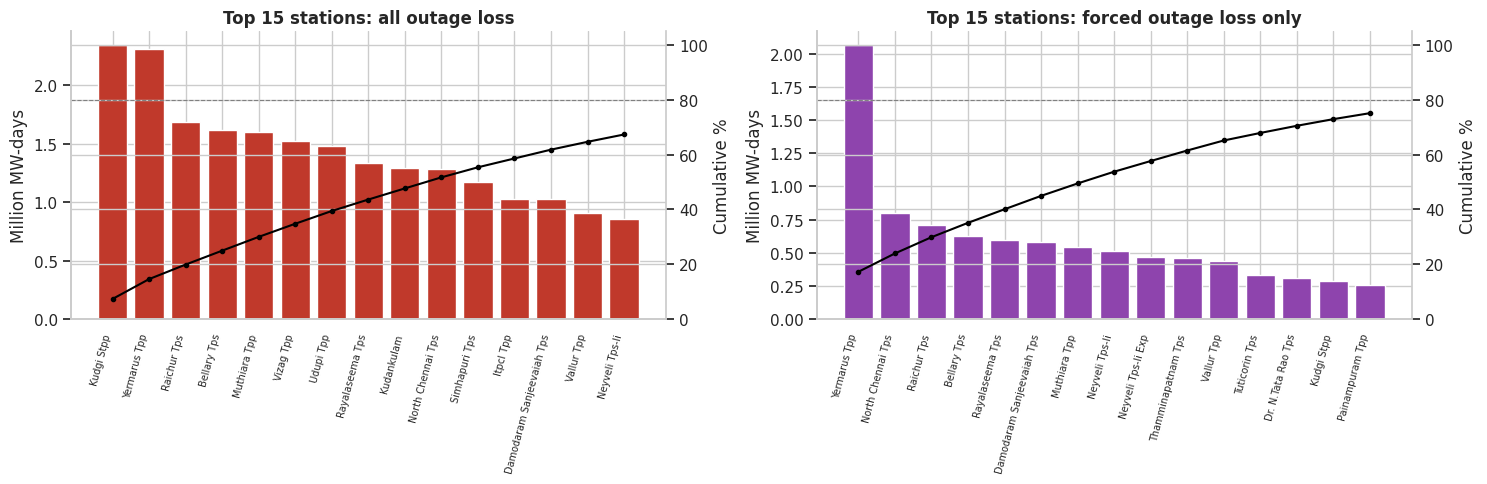

47 stations have outage loss. Top 5 = 30%, top 10 = 52%, top 20 = 78% of all outage loss; 21 stations make up 80%.
Forced outages only: top 10 = 62% ; 18 stations make up 80%.
         power_station      state_name     fuel_type  capacity_mw  loss_MW_days  forced_MW_days  forced_share_%
54          Kudgi Stpp       Karnataka  Coal/Lignite       800.00  2,344,800.00      290,400.00           12.38
163       Yermarus Tpp       Karnataka  Coal/Lignite       800.00  2,310,400.00    2,066,400.00           89.44
118        Raichur Tps       Karnataka  Coal/Lignite       250.00  1,690,190.00      709,580.00           41.98
6          Bellary Tps       Karnataka  Coal/Lignite       700.00  1,618,300.00      627,400.00           38.77
84        Muthiara Tpp      Tamil Nadu  Coal/Lignite       600.00  1,603,200.00      542,400.00           33.83
159          Vizag Tpp  Andhra Pradesh  Coal/Lignite       520.00  1,527,760.00       95,680.00            6.26
151          Udupi Tpp       Karnataka  

In [ ]:
def pareto(frame, title, color, ax):
    s = (frame.groupby('power_station').outage_loss_mw.sum().sort_values(ascending=False))
    s = s[s > 0]; cum = s.cumsum() / s.sum() * 100
    n80 = int((cum < 80).sum() + 1)
    top = s.head(15)
    ax.bar(range(len(top)), top.values / 1e6, color=color)
    ax.set_xticks(range(len(top))); ax.set_xticklabels(top.index, rotation=75, ha='right', fontsize=7)
    ax.set_ylabel('Million MW-days'); ax.set_title(title)
    ax2 = ax.twinx(); ax2.plot(range(len(top)), cum.head(15).values, color='black', marker='o', ms=3); ax2.set_ylim(0, 105)
    ax2.set_ylabel('Cumulative %'); ax2.axhline(80, ls='--', color='grey', lw=0.8); ax2.spines['right'].set_visible(True)
    return s, cum, n80

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
s_all, c_all, n80_all = pareto(df, 'Top 15 stations: all outage loss', '#c0392b', ax[0])
forced_rows = df[df.cause_category == 'Technical (forced)']
s_f, c_f, n80_f = pareto(forced_rows, 'Top 15 stations: forced outage loss only', '#8e44ad', ax[1])
plt.tight_layout(); plt.show()

print(f'{len(s_all)} stations have outage loss. Top 5 = {c_all.iloc[4]:.0f}%, top 10 = {c_all.iloc[9]:.0f}%, top 20 = {c_all.iloc[19]:.0f}% of all outage loss; {n80_all} stations make up 80%.')
print(f'Forced outages only: top 10 = {c_f.iloc[9]:.0f}% ; {n80_f} stations make up 80%.')

stn = df.groupby(['power_station', 'state_name', 'fuel_type']).agg(capacity_mw=('monitored_capacity', 'max'),
        loss_MW_days=('outage_loss_mw', 'sum')).reset_index()
stn = stn.merge(forced_rows.groupby('power_station').outage_loss_mw.sum().rename('forced_MW_days'), on='power_station', how='left').fillna({'forced_MW_days': 0})
stn['forced_share_%'] = stn.forced_MW_days / stn.loss_MW_days * 100
display(stn.sort_values('loss_MW_days', ascending=False).head(10).style.format(
    {'capacity_mw': '{:,.0f}', 'loss_MW_days': '{:,.0f}', 'forced_MW_days': '{:,.0f}', 'forced_share_%': '{:.0f}%'}))

### 10.3 Repeat failures: units that trip again soon after returning
For each unit, forced episodes are sorted by date. A **repeat** is a forced outage that starts within 30 days of the previous episode ending. High repeat rates point to fixes that did not hold (e.g. boiler tube leaks patched but not cured).

Forced episodes: 5,090 across 151 units. 2,827 of 4,939 follow-on trips (57%) start within 30 days of the previous one ending.
Median gap between a unit returning and its next forced trip: 23 days.
Of the repeat trips, 24% carry the SAME remark as the trip before (same fault not cured).
                             forced_episodes  repeats  capacity_mw           state          fuel  repeat_%  trips_per_year
unit                                                                                                                      
Neyveli Tps-Ii Exp | Unit 2              104       94       250.00      Tamil Nadu  Coal/Lignite     90.38           15.45
Neyveli Tps-Ii Exp | Unit 1               96       85       250.00      Tamil Nadu  Coal/Lignite     88.54           14.26
Ramagundem-B Tps | Unit 1                104       85        62.50       Telangana  Coal/Lignite     81.73           15.45
Tuticorin Tps | Unit 2                   100       80       210.00      Tamil Nadu  Coal/Lignite 

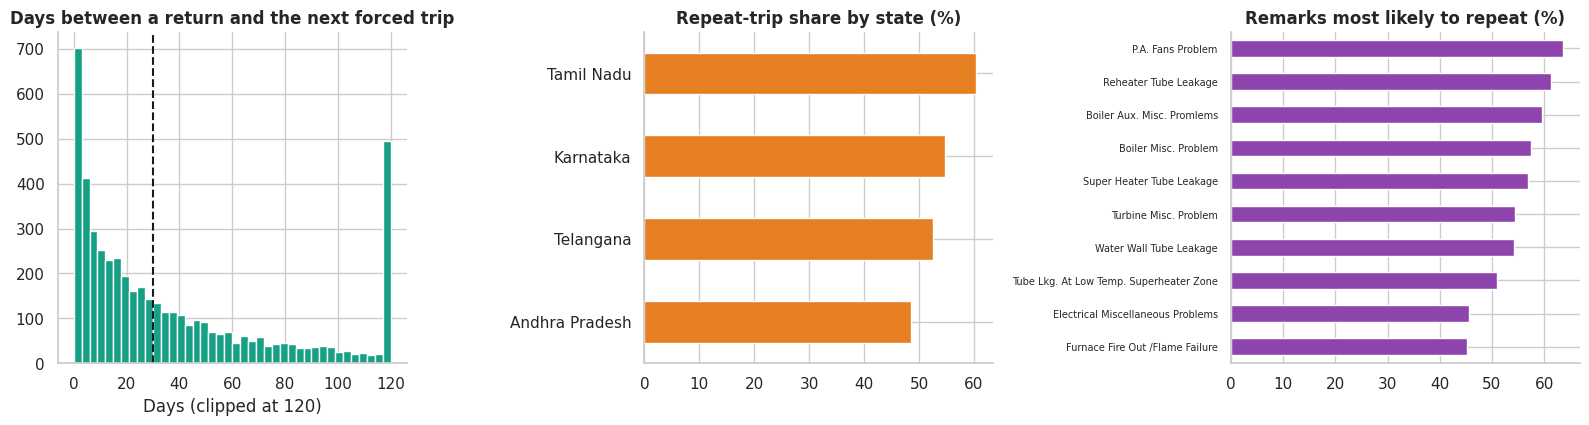

In [ ]:
f = episodes[episodes.cause == 'Technical (forced)'].copy()
f['unit'] = f.power_station + ' | ' + f.power_station_unit
f = f.sort_values(['unit', 'outage_date'])
f['prev_end'] = f.groupby('unit').last_seen.shift()
f['gap_days'] = (f.outage_date - f.prev_end).dt.days
f['is_repeat'] = f.gap_days.between(0, 30)               # negative gaps (overlapping records) are not counted as repeats

has_prev = f.gap_days.notna()
print(f'Forced episodes: {len(f):,} across {f.unit.nunique()} units. '
      f'{f.is_repeat.sum():,} of {has_prev.sum():,} follow-on trips ({f.is_repeat.sum() / has_prev.sum():.0%}) start within 30 days of the previous one ending.')
print(f'Median gap between a unit returning and its next forced trip: {f.loc[f.gap_days >= 0, "gap_days"].median():.0f} days.')

# Does the same remark come back?
f['prev_remark'] = f.groupby('unit').remark.shift()
same = (f.remark == f.prev_remark) & f.is_repeat
print(f'Of the repeat trips, {same.sum() / f.is_repeat.sum():.0%} carry the SAME remark as the trip before (same fault not cured).')

by_unit = f.groupby('unit').agg(forced_episodes=('unit', 'size'), repeats=('is_repeat', 'sum'), capacity_mw=('capacity_mw', 'max'),
                                state=('state', 'first'), fuel=('fuel', 'first'))
by_unit['repeat_%'] = by_unit.repeats / by_unit.forced_episodes * 100
by_unit['trips_per_year'] = by_unit.forced_episodes / (df.date.nunique() / 365.25)
display(by_unit.sort_values('repeats', ascending=False).head(10).style.format(
    {'capacity_mw': '{:,.0f}', 'repeat_%': '{:.0f}%', 'trips_per_year': '{:.1f}'}))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].hist(f.gap_days.dropna().clip(0, 120), bins=40, color='#16a085'); ax[0].axvline(30, ls='--', color='k')
ax[0].set_title('Days between a return and the next forced trip'); ax[0].set_xlabel('Days (clipped at 120)')
rs = f.groupby('state').agg(n=('is_repeat', 'size'), r=('is_repeat', 'mean')); rs = rs[rs.n >= 30]
(rs.r * 100).sort_values().plot(kind='barh', ax=ax[1], color='#e67e22'); ax[1].set_title('Repeat-trip share by state (%)'); ax[1].set_ylabel('')
(f.groupby('remark').is_repeat.agg(['size', 'mean']).query('size >= 80')['mean'] * 100).sort_values().tail(10).plot(kind='barh', ax=ax[2], color='#8e44ad')
ax[2].set_title('Remarks most likely to repeat (%)'); ax[2].set_ylabel(''); ax[2].tick_params(axis='y', labelsize=7)
plt.tight_layout(); plt.show()

### 10.4 Kaplan–Meier recovery curves (handles still-ongoing outages)
Averages of recovery time ignore outages that never ended inside the data window. A **survival curve** treats them as *censored*: the curve shows the probability that an outage is **still on** after *t* days. The estimator is written out directly (no `lifelines` needed); the result is the standard product-limit estimate.

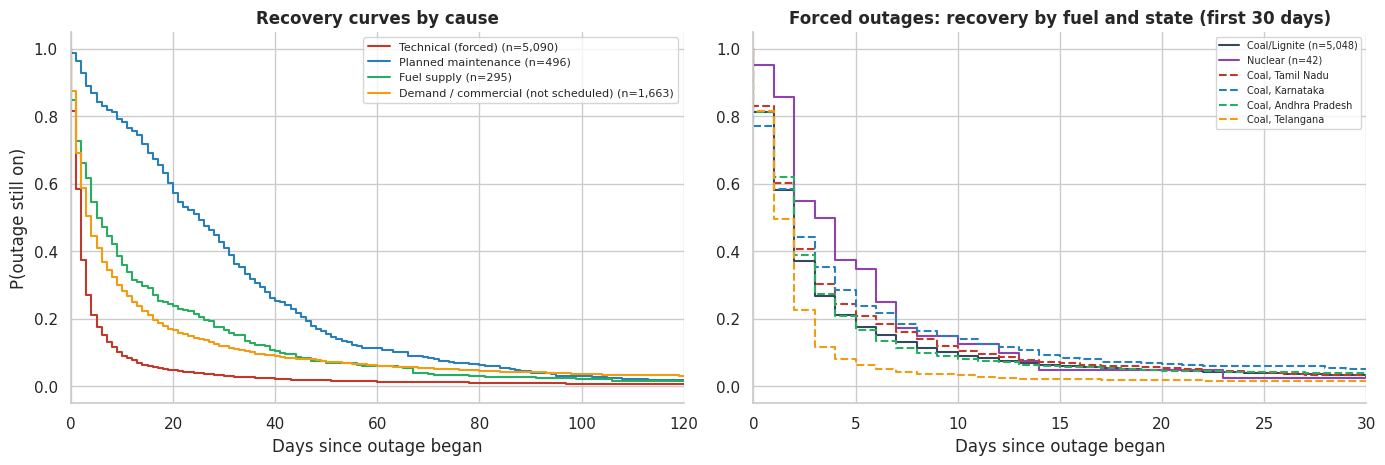

                                     episodes  KM_median_days  still_down_after_7d_%  still_down_after_30d_%  still_down_after_90d_%
cause                                                                                                                               
Technical (forced)                       5090            2.00                  13.14                    3.13                    0.90
Planned maintenance                       496           25.00                  81.85                   40.96                    4.09
Fuel supply                               295            5.00                  44.41                   16.61                    2.71
Demand / commercial (not scheduled)      1663            4.00                  34.49                   11.86                    4.21


In [ ]:
def kaplan_meier(durations, recovered):
    d = np.asarray(durations, float); e = np.asarray(recovered, bool)
    times = np.unique(d[e]); S, rows = 1.0, [(0.0, 1.0)]
    for t in times:
        at_risk = (d >= t).sum(); events = ((d == t) & e).sum()
        S *= 1 - events / at_risk; rows.append((t, S))
    return pd.DataFrame(rows, columns=['t', 'S'])

def surv_at(km, t): return km.loc[km.t <= t, 'S'].iloc[-1]
def km_median(km): 
    m = km.loc[km.S <= 0.5, 't']; return m.min() if len(m) else np.nan

ep_km = episodes.assign(dur=episodes.duration_days.clip(lower=0))
GROUPS = ['Technical (forced)', 'Planned maintenance', 'Fuel supply', 'Demand / commercial (not scheduled)']
cols = dict(zip(GROUPS, ['#c0392b', '#2980b9', '#27ae60', '#f39c12']))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
rows = []
for g in GROUPS:
    s = ep_km[ep_km.cause == g]; k = kaplan_meier(s.dur, s.recovered)
    ax[0].step(k.t, k.S, where='post', label=f'{g} (n={len(s):,})', color=cols[g])
    rows.append({'cause': g, 'episodes': len(s), 'KM_median_days': km_median(k), 'still_down_after_7d_%': surv_at(k, 7) * 100,
                 'still_down_after_30d_%': surv_at(k, 30) * 100, 'still_down_after_90d_%': surv_at(k, 90) * 100})
ax[0].set_xlim(0, 120); ax[0].set_xlabel('Days since outage began'); ax[0].set_ylabel('P(outage still on)')
ax[0].set_title('Recovery curves by cause'); ax[0].legend(fontsize=8)

forced_ep = ep_km[ep_km.cause == 'Technical (forced)']
for fu, c in zip(['Coal/Lignite', 'Nuclear'], ['#34495e', '#8e44ad']):
    s = forced_ep[forced_ep.fuel == fu]
    if len(s) >= 30:
        k = kaplan_meier(s.dur, s.recovered); ax[1].step(k.t, k.S, where='post', label=f'{fu} (n={len(s):,})', color=c)
for st_, c in zip(['Tamil Nadu', 'Karnataka', 'Andhra Pradesh', 'Telangana'], ['#c0392b', '#2980b9', '#27ae60', '#f39c12']):
    s = forced_ep[(forced_ep.state == st_) & (forced_ep.fuel == 'Coal/Lignite')]
    k = kaplan_meier(s.dur, s.recovered); ax[1].step(k.t, k.S, where='post', ls='--', label=f'Coal, {st_}', color=c)
ax[1].set_xlim(0, 30); ax[1].set_xlabel('Days since outage began'); ax[1].set_title('Forced outages: recovery by fuel and state (first 30 days)'); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index('cause').style.format({'episodes': '{:,.0f}', 'KM_median_days': '{:.0f}', 'still_down_after_7d_%': '{:.1f}',
                                                              'still_down_after_30d_%': '{:.1f}', 'still_down_after_90d_%': '{:.1f}'}))

### 10.5 Expected vs actual synchronisation date
Does the *first* expected sync date a station reports hold up? Slippage = actual return (last day seen) minus first expected date. Positive means later than promised.

8,362 recovered episodes have an expected sync date (88% of recovered episodes).
Within +/-2 days of first estimate: 95% | later than expected by more than 7 days: 2.6% | later by more than 30 days: 0.9%
                                         episodes  mean_slip  p90_slip  late_over_7d_pct
cause                                                                                   
Planned maintenance                           422       7.91     13.90             12.32
Demand / commercial (not scheduled)          1366       6.87      2.00              6.22
Fuel supply                                   253       1.77      0.00              4.74
Technical (forced)                           4453       0.96      0.00              1.59
Financial / legal                               2       0.00      0.00              0.00
Not recorded                                 1865      -0.01      0.00              0.00
Not operational (new/unstabilised unit)         1       0.00      0.00              

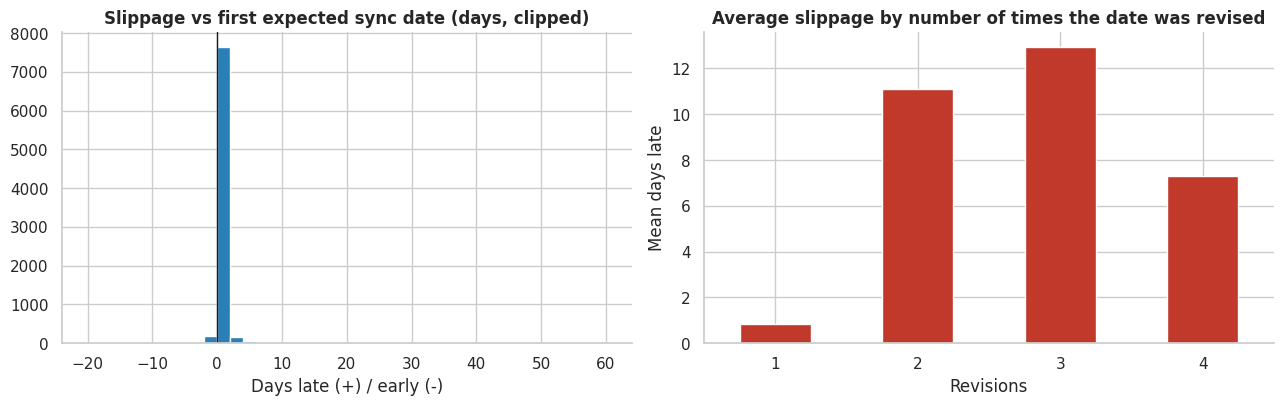

In [ ]:
ex = (df[df.outage_date.notna() & ~df.shortfall_not_outage & df.expected_sync_date.notna()].sort_values('date')
        .groupby(key).agg(first_expected=('expected_sync_date', 'first'), times_revised=('expected_sync_date', 'nunique')).reset_index())
sl = episodes.merge(ex, on=key, how='inner'); sl = sl[sl.recovered].copy()
sl['slip_days'] = (sl.last_seen - sl.first_expected).dt.days
print(f'{len(sl):,} recovered episodes have an expected sync date ({len(sl) / episodes.recovered.sum():.0%} of recovered episodes).')
print(f'Within +/-2 days of first estimate: {(sl.slip_days.abs() <= 2).mean():.0%} | later than expected by more than 7 days: {(sl.slip_days > 7).mean():.1%} | '
      f'later by more than 30 days: {(sl.slip_days > 30).mean():.1%}')

slip = sl.groupby('cause').agg(episodes=('slip_days', 'size'), mean_slip=('slip_days', 'mean'), p90_slip=('slip_days', lambda s: s.quantile(.9)),
                               late_over_7d_pct=('slip_days', lambda s: (s > 7).mean() * 100)).sort_values('late_over_7d_pct', ascending=False)
display(slip.style.format({'episodes': '{:,.0f}', 'mean_slip': '{:.1f}', 'p90_slip': '{:.1f}', 'late_over_7d_pct': '{:.1f}%'}))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(sl.slip_days.clip(-20, 60), bins=40, color='#2980b9'); ax[0].axvline(0, color='k', lw=1)
ax[0].set_title('Slippage vs first expected sync date (days, clipped)'); ax[0].set_xlabel('Days late (+) / early (-)')
(sl.groupby('times_revised').slip_days.agg(['size', 'mean']).query('size >= 20')['mean']).head(10).plot(kind='bar', ax=ax[1], color='#c0392b')
ax[1].set_title('Average slippage by number of times the date was revised'); ax[1].set_xlabel('Revisions'); ax[1].set_ylabel('Mean days late'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Caution on this section:** the first estimate is hit within 2 days for almost every episode, which is more accurate than real boiler repairs usually are. The `expected_sync_date` field may be overwritten with the actual date once the unit returns, so treat this as a **data-quality check** rather than proof that station forecasts are reliable. Long outages (the ones that slip) are the only meaningful signal here.

### 10.6 Monthly forecast of average daily outage loss (with a backtest)
Three simple models are compared on a hold-out year: **seasonal naive** (same month last year), **month profile + linear trend**, and **additive Holt-Winters** (grid-searched). December 2024 is dropped because only 10 days exist. The model that wins the backtest forecasts 2025.

Backtest on Jan to Nov 2024 (trained on 2018 to 2023):
                               MAPE_%   MAE_MW
Seasonal naive                  22.73 1,747.15
Month profile + trend           17.89 1,307.55
Holt-Winters (0.5, 0.01, 0.5)   25.11 2,064.37
Best model: Month profile + trend


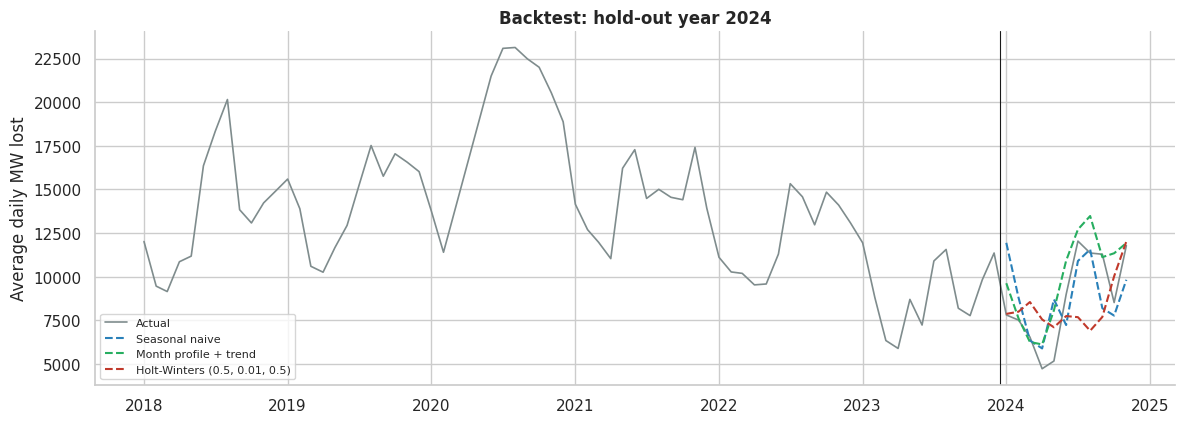

In [ ]:
ms = (df.groupby(df.date.dt.to_period('M')).agg(mw=('outage_loss_mw', 'sum'), d=('date', 'nunique')))
ms = ms[ms.d >= 28]; y = (ms.mw / ms.d); y.index = y.index.to_timestamp()        # drops Dec 2024 (10 days)
train, test = y[:'2023-12'], y['2024-01':]

def seasonal_naive(tr, h): return np.array([tr.iloc[-12 + (i % 12)] for i in range(h)])

def trend_profile(tr, h):
    t = np.arange(len(tr)); X = np.column_stack([t, np.eye(12)[tr.index.month - 1]])
    beta = np.linalg.lstsq(X, tr.values, rcond=None)[0]
    tf = np.arange(len(tr), len(tr) + h); months = (tr.index[-1].month + np.arange(1, h + 1) - 1) % 12
    return np.column_stack([tf, np.eye(12)[months]]) @ beta

def holt_winters(tr, h, alpha, beta, gamma, m=12):
    v = tr.values; lvl = v[:m].mean(); tr_ = (v[m:2*m].mean() - v[:m].mean()) / m; seas = list(v[:m] - lvl)
    for i, x in enumerate(v):
        s = seas[i % m] if i < m else seas[i]
        new_lvl = alpha * (x - s) + (1 - alpha) * (lvl + tr_)
        tr_ = beta * (new_lvl - lvl) + (1 - beta) * tr_; seas.append(gamma * (x - new_lvl) + (1 - gamma) * s); lvl = new_lvl
    return np.array([lvl + (i + 1) * tr_ + seas[len(v) + i - m] for i in range(h)])

def sse_hw(tr, params):
    a, b, g = params; fit = []
    v = tr.values; m = 12; lvl = v[:m].mean(); tr_ = (v[m:2*m].mean() - v[:m].mean()) / m; seas = list(v[:m] - lvl); err = 0
    for i, x in enumerate(v):
        s = seas[i]; pred = lvl + tr_ + s
        if i >= m: err += (x - pred) ** 2
        new_lvl = a * (x - s) + (1 - a) * (lvl + tr_); tr_ = b * (new_lvl - lvl) + (1 - b) * tr_
        seas.append(g * (x - new_lvl) + (1 - g) * s); lvl = new_lvl
    return err

grid = [(a, b, g) for a in (0.1, 0.3, 0.5) for b in (0.01, 0.05, 0.1) for g in (0.1, 0.3, 0.5)]
best = min(grid, key=lambda p: sse_hw(train, p))

h = len(test)
preds = {'Seasonal naive': seasonal_naive(train, h), 'Month profile + trend': trend_profile(train, h), f'Holt-Winters {best}': holt_winters(train, h, *best)}
score = pd.DataFrame({k: {'MAPE_%': np.mean(np.abs(test.values - p) / test.values) * 100, 'MAE_MW': np.mean(np.abs(test.values - p))}
                      for k, p in preds.items()}).T
print('Backtest on Jan to Nov 2024 (trained on 2018 to 2023):'); display(score.style.format({'MAPE_%': '{:.1f}', 'MAE_MW': '{:,.0f}'}))

winner = score['MAPE_%'].idxmin(); print('Best model:', winner)
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(y.index, y.values, color='#7f8c8d', lw=1.2, label='Actual')
for (k, p), c in zip(preds.items(), ['#2980b9', '#27ae60', '#c0392b']): ax.plot(test.index, p, ls='--', color=c, label=k)
ax.axvline(pd.Timestamp('2023-12-15'), color='k', lw=0.8); ax.set_ylabel('Average daily MW lost'); ax.set_title('Backtest: hold-out year 2024'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

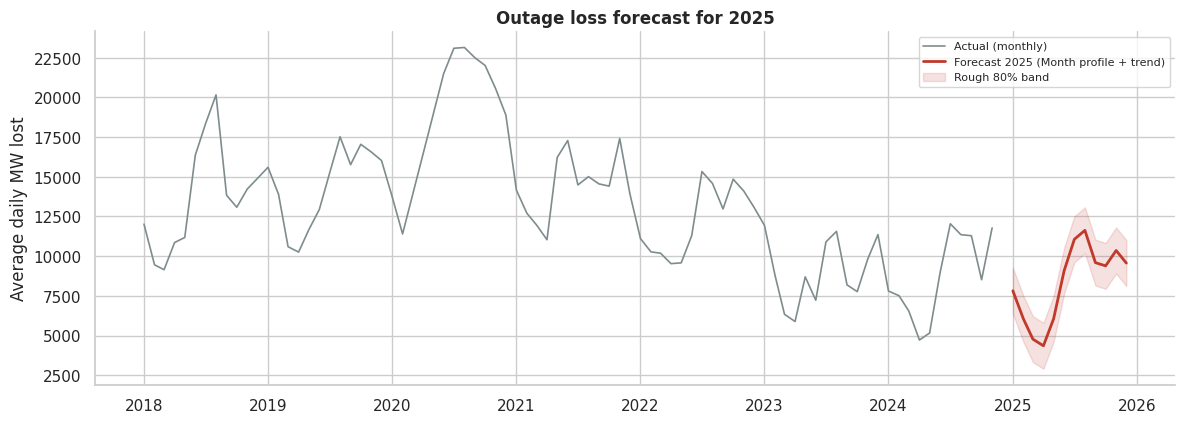

                       Jan 2025  Feb 2025  Mar 2025  Apr 2025  May 2025  Jun 2025  Jul 2025  Aug 2025  Sep 2025  Oct 2025  Nov 2025  Dec 2025
forecast_avg_daily_MW  7,816.11  6,050.37  4,770.50  4,354.38  6,056.66  9,087.99 11,059.54 11,621.81  9,588.97  9,386.36 10,353.95  9,560.68
Forecast peak month: Aug 2025 (11,622 MW/day); lowest: Apr 2025.


In [ ]:
# Refit the winning model on all data (Jan 2018 to Nov 2024) and forecast 2025 (Dec 2024 is generated first, then dropped)
H = 13; idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq='MS')
best_all = min(grid, key=lambda p: sse_hw(y, p))
fc_fun = {'Seasonal naive': lambda: seasonal_naive(y, H), 'Month profile + trend': lambda: trend_profile(y, H)}
fc = fc_fun[winner]() if winner in fc_fun else holt_winters(y, H, *best_all)
fc, idx = fc[1:], idx[1:]                                                          # keep Jan to Dec 2025
resid = test.values - preds[winner]; band = 1.28 * resid.std()                      # rough 80% band from backtest errors

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(y.index, y.values, color='#7f8c8d', lw=1.2, label='Actual (monthly)')
ax.plot(idx, fc, color='#c0392b', lw=2, label=f'Forecast 2025 ({winner.split(" (")[0]})')
ax.fill_between(idx, fc - band, fc + band, color='#c0392b', alpha=0.15, label='Rough 80% band')
ax.set_ylabel('Average daily MW lost'); ax.set_title('Outage loss forecast for 2025'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
fc_tbl = pd.DataFrame({'forecast_avg_daily_MW': fc}, index=idx.strftime('%b %Y')); display(fc_tbl.T.style.format('{:,.0f}'))
print(f'Forecast peak month: {fc_tbl.forecast_avg_daily_MW.idxmax()} ({fc_tbl.forecast_avg_daily_MW.max():,.0f} MW/day); lowest: {fc_tbl.forecast_avg_daily_MW.idxmin()}.')

**Read the forecast with care.** It forecasts *total* outage loss, which includes the commercial / reserve-shutdown component that swung from about 11,000 MW/day in 2020 to under 2,000 in 2024. A backtest MAPE near 18% reflects that noise. Forced outage loss alone is almost flat (Section 10.1), so forecasting forced loss per state or station is the more useful next version.

### 10.7 What this adds to the story

In [ ]:
share = overall_share
print('A) LOSS COMPOSITION')
print(f'   Forced equipment trouble is {share["Technical (forced)"]:.0f}% of outage loss; planned maintenance {share["Planned maintenance"]:.0f}%; '
      f'commercial / reserve shutdown {share["Demand / commercial (not scheduled)"]:.0f}%; fuel supply {share["Fuel supply"]:.0f}%.')
print('B) CONCENTRATION')
print(f'   {n80_all} of {len(s_all)} stations account for 80% of outage loss; top 10 = {c_all.iloc[9]:.0f}%.')
print('C) REPEAT TRIPS')
print(f'   {f.is_repeat.sum() / has_prev.sum():.0%} of forced trips start within 30 days of the previous one; {same.sum() / f.is_repeat.sum():.0%} of those repeat the same remark.')
print('D) SURVIVAL')
print('   ' + '; '.join(f'{r["cause"]}: median {r["KM_median_days"]:.0f} d, {r["still_down_after_30d_%"]:.0f}% still down at 30 d' for r in rows))
print('E) SYNC DATE')
print(f'   {(sl.slip_days.abs() <= 2).mean():.0%} of episodes return within 2 days of the first expected date (check how this field is populated).')
print('F) FORECAST')
print(f'   Best backtest model: {winner} (MAPE {score["MAPE_%"].min():.1f}%). Expected 2025 peak: {fc_tbl.forecast_avg_daily_MW.idxmax()}.')

A) LOSS COMPOSITION
   Forced equipment trouble is 38% of outage loss; planned maintenance 20%; commercial / reserve shutdown 34%; fuel supply 7%.
B) CONCENTRATION
   21 of 47 stations account for 80% of outage loss; top 10 = 52%.
C) REPEAT TRIPS
   57% of forced trips start within 30 days of the previous one; 24% of those repeat the same remark.
D) SURVIVAL
   Technical (forced): median 2 d, 3% still down at 30 d; Planned maintenance: median 25 d, 41% still down at 30 d; Fuel supply: median 5 d, 17% still down at 30 d; Demand / commercial (not scheduled): median 4 d, 12% still down at 30 d
E) SYNC DATE
   95% of episodes return within 2 days of the first expected date (check how this field is populated).
F) FORECAST
   Best backtest model: Month profile + trend (MAPE 17.9%). Expected 2025 peak: Aug 2025.
